<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

<h1 align="center"><b>Concentración de CO<sub>2</sub> en Mauna Loa: modelos SARIMA </b></h1>

---

**Series de Tiempo I** · Universidad de Antioquia · 2026-2
Juan Camilo Melo Ortíz

La serie `co2` viene incluida en R (paquete `datasets`). Son las **concentraciones atmosféricas mensuales de CO<sub>2</sub>**, en partes por millón (ppm), medidas en el observatorio de **Mauna Loa (Hawái)** entre **enero de 1959 y diciembre de 1997**, es decir, 468 observaciones. Es la famosa curva de Keeling: el CO<sub>2</sub> sube año tras año y además "respira" dentro de cada año, porque en el verano del hemisferio norte la vegetación absorbe carbono y en el invierno lo devuelve.

La idea es seguir la misma ruta de los notebooks del curso (Amazon, Cmort y Air Passengers):

1. Análisis descriptivo y gráficos estacionales.
2. Suavizamiento con medias móviles y descomposición.
3. Homogeneidad de varianzas (Levene y Box-Cox).
4. Pruebas de estacionariedad y diferenciación.
5. Identificación con ACF, PACF y criterios de información.
6. Estimación de los modelos candidatos.
7. Diagnóstico residual.
8. Pronóstico.
9. Capacidad de pronóstico (trayectoria ajustada, partición y validación cruzada).

</div>

---

## **Librerías y Carga de los Datos**

In [1]:
# Instalar solo las librerías que falten #
paquetes <- c("stats", "astsa", "forecast", "tseries", "nortest", "fBasics", "car",
              "MLmetrics", "ggplot2", "gridExtra", "pastecs", "lmtest")
faltan <- paquetes[!paquetes %in% rownames(installed.packages())]
if (length(faltan) > 0) install.packages(faltan, repos = "https://cloud.r-project.org")

In [2]:
# Cargar Librerías #
suppressPackageStartupMessages({
  library(stats)
  library(astsa)      # sarima() y acf2()
  library(forecast)   # Arima(), auto.arima(), forecast(), ets()
  library(tseries)    # adf.test() y kpss.test()
  library(nortest)    # lillie.test()
  library(fBasics)    # jarqueberaTest()
  library(car)        # leveneTest(), qqPlot() y powerTransform()
  library(MLmetrics)  # MAPE()
  library(ggplot2)
  library(gridExtra)
  library(pastecs)    # buysbal(): tabla Buys-Ballot
  library(lmtest)     # coeftest()
})

options(repr.plot.width = 14, repr.plot.height = 7, warn = -1)

# Carpeta para guardar las figuras principales #
dir_fig <- "../figuras"
dir.create(dir_fig, showWarnings = FALSE)
guardar <- function(g, nombre, ancho = 12, alto = 6) {
  ggsave(file.path(dir_fig, nombre), g, width = ancho, height = alto, dpi = 120, bg = "white")
}

In [3]:
# Función auxiliar: ACF y PACF en ggplot (el mismo estilo de los notebooks del curso) #
graf_acf_pacf <- function(x, lags = 48, titulo = "") {
  x <- as.numeric(na.omit(x))
  n <- length(x)
  ci <- qnorm(0.975) / sqrt(n)
  acf_vals  <- acf(x, lag.max = lags, plot = FALSE)$acf[-1]
  pacf_vals <- pacf(x, lag.max = lags, plot = FALSE)$acf[, 1, 1]
  df <- rbind(data.frame(Panel = "ACF",  Rezago = 1:lags, Valor = acf_vals),
              data.frame(Panel = "PACF", Rezago = 1:lags, Valor = pacf_vals))
  ggplot(df, aes(x = Rezago, y = Valor)) +
    geom_segment(aes(xend = Rezago, yend = 0), color = "steelblue", linewidth = 1) +
    geom_hline(yintercept = 0) +
    geom_hline(yintercept = c(-ci, ci), linetype = "dashed", color = "red") +
    geom_vline(xintercept = seq(12, lags, 12), linetype = "dotted", color = "grey50") +
    scale_x_continuous(breaks = seq(0, lags, 6)) +
    facet_wrap(~ Panel, ncol = 1) +
    labs(title = titulo, x = "Rezago (meses)", y = "") +
    theme_minimal(base_size = 13) +
    theme(plot.title = element_text(hjust = 0.5, face = "bold"))
}

In [4]:
# Carga de datos #
data(co2)
co2_ts <- co2
n <- length(co2_ts)
paste("Número de observaciones mensuales:", n)
paste("Desde", paste(start(co2_ts), collapse = "-"), "hasta", paste(end(co2_ts), collapse = "-"),
      "con frecuencia", frequency(co2_ts))
summary(co2_ts)

[1] "Número de observaciones mensuales: 468"

[1] "Desde 1959-1 hasta 1997-12 con frecuencia 12"

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  313.2   323.5   335.2   337.1   350.3   366.8 

---
<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

<h1 align="center"><b>1. Análisis Descriptivo </b></h1>

</div>

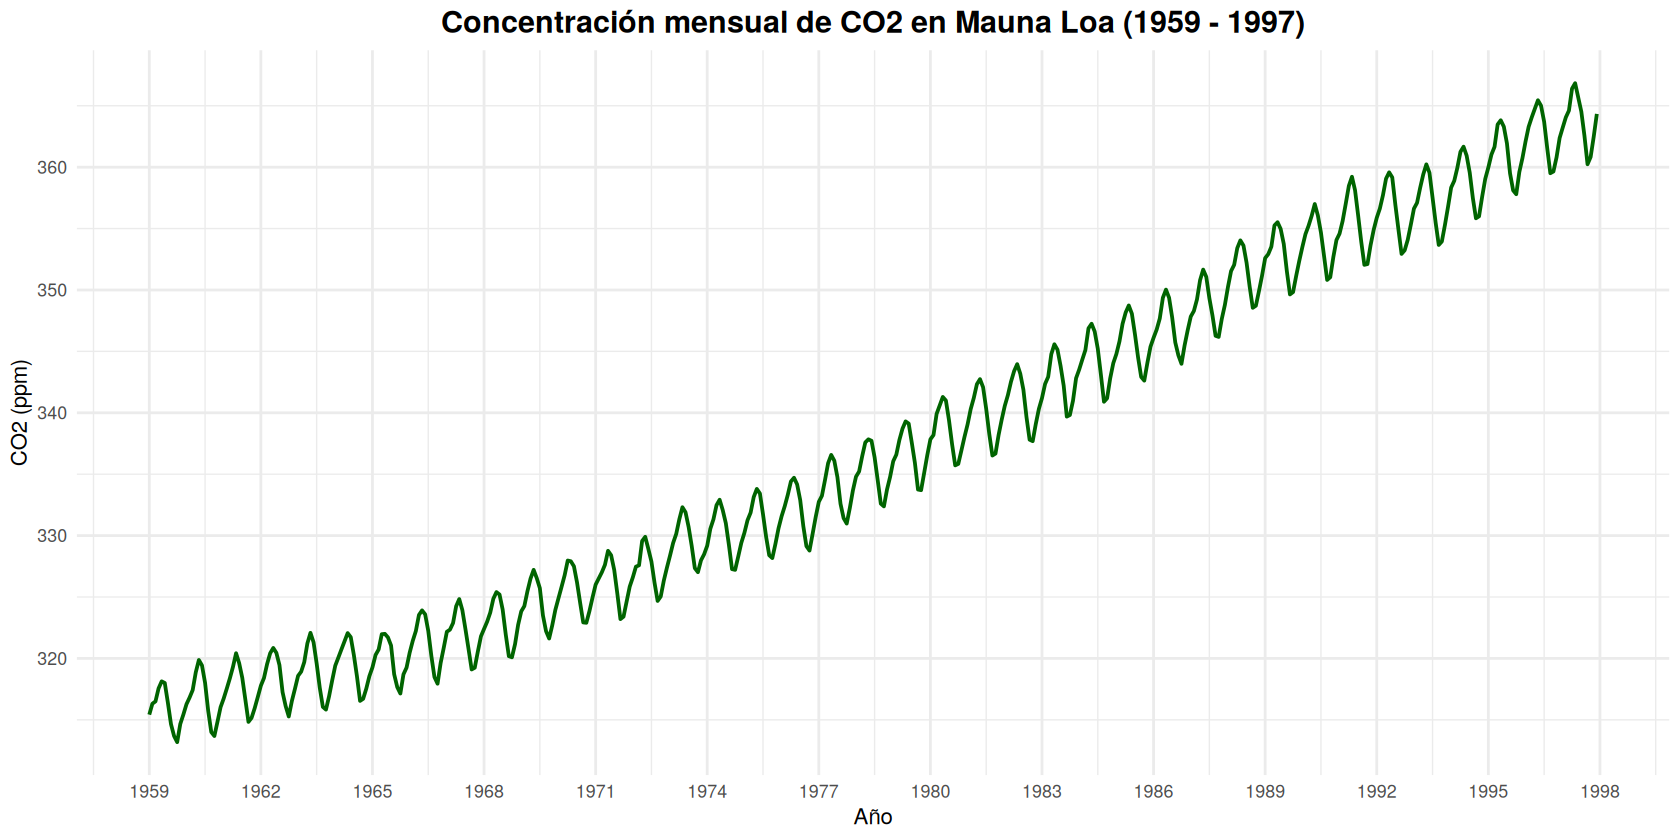

In [5]:
# Gráfico de la serie #
df_co2 <- data.frame(Tiempo = as.numeric(time(co2_ts)), CO2 = as.numeric(co2_ts))
g_serie <- ggplot(df_co2, aes(x = Tiempo, y = CO2)) +
  geom_line(color = "darkgreen", linewidth = 0.8) +
  labs(title = "Concentración mensual de CO2 en Mauna Loa (1959 - 1997)",
       x = "Año", y = "CO2 (ppm)") +
  scale_x_continuous(breaks = seq(1959, 1998, 3)) +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5, size = 18, face = "bold"))
guardar(g_serie, "serie_co2.png")
g_serie

<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

**Lo que se ve a simple vista:**

- Una **tendencia creciente** muy marcada: el CO<sub>2</sub> pasa de unos 315 ppm a casi 367 ppm en 39 años, y la pendiente parece aumentar un poco con el tiempo.
- Una **estacionalidad anual** ($S = 12$) muy regular: cada año hay un pico y un valle.
- La amplitud del ciclo anual se ve **más o menos constante**, o sea que la estacionalidad parece aditiva y no multiplicativa como en Air Passengers. Eso lo confirmamos más adelante con Levene.

</div>

In [6]:
# Tabla Buys-Ballot (library pastecs): filas = años, columnas = meses #
tb_bb <- buysbal(co2_ts, y = NULL, frequency = 12, dateformat = "m/Y")
round(tb_bb, 2)

,1,2,3,4,5,6,7,8,9,10,11,12
1959,315.42,316.31,316.50,317.56,318.13,318.00,316.39,314.65,313.68,313.18,314.66,315.43
1960,316.27,316.81,317.42,318.87,319.87,319.43,318.01,315.74,314.00,313.68,314.84,316.03
1961,316.73,317.54,318.38,319.31,320.42,319.61,318.42,316.63,314.83,315.16,315.94,316.85
1962,317.78,318.40,319.53,320.42,320.85,320.45,319.45,317.25,316.11,315.27,316.53,317.53
1963,318.58,318.92,319.70,321.22,322.08,321.31,319.58,317.61,316.05,315.83,316.91,318.20
1964,319.41,320.07,320.74,321.40,322.06,321.73,320.27,318.54,316.54,316.71,317.53,318.55
1965,319.27,320.28,320.73,321.97,322.00,321.71,321.05,318.71,317.66,317.14,318.70,319.25
1966,320.46,321.43,322.23,323.54,323.91,323.59,322.24,320.20,318.48,317.94,319.63,320.87
1967,322.17,322.34,322.88,324.25,324.83,323.93,322.38,320.76,319.10,319.24,320.56,321.80
1968,322.40,322.99,323.73,324.86,325.40,325.20,323.98,321.95,320.18,320.09,321.16,322.74


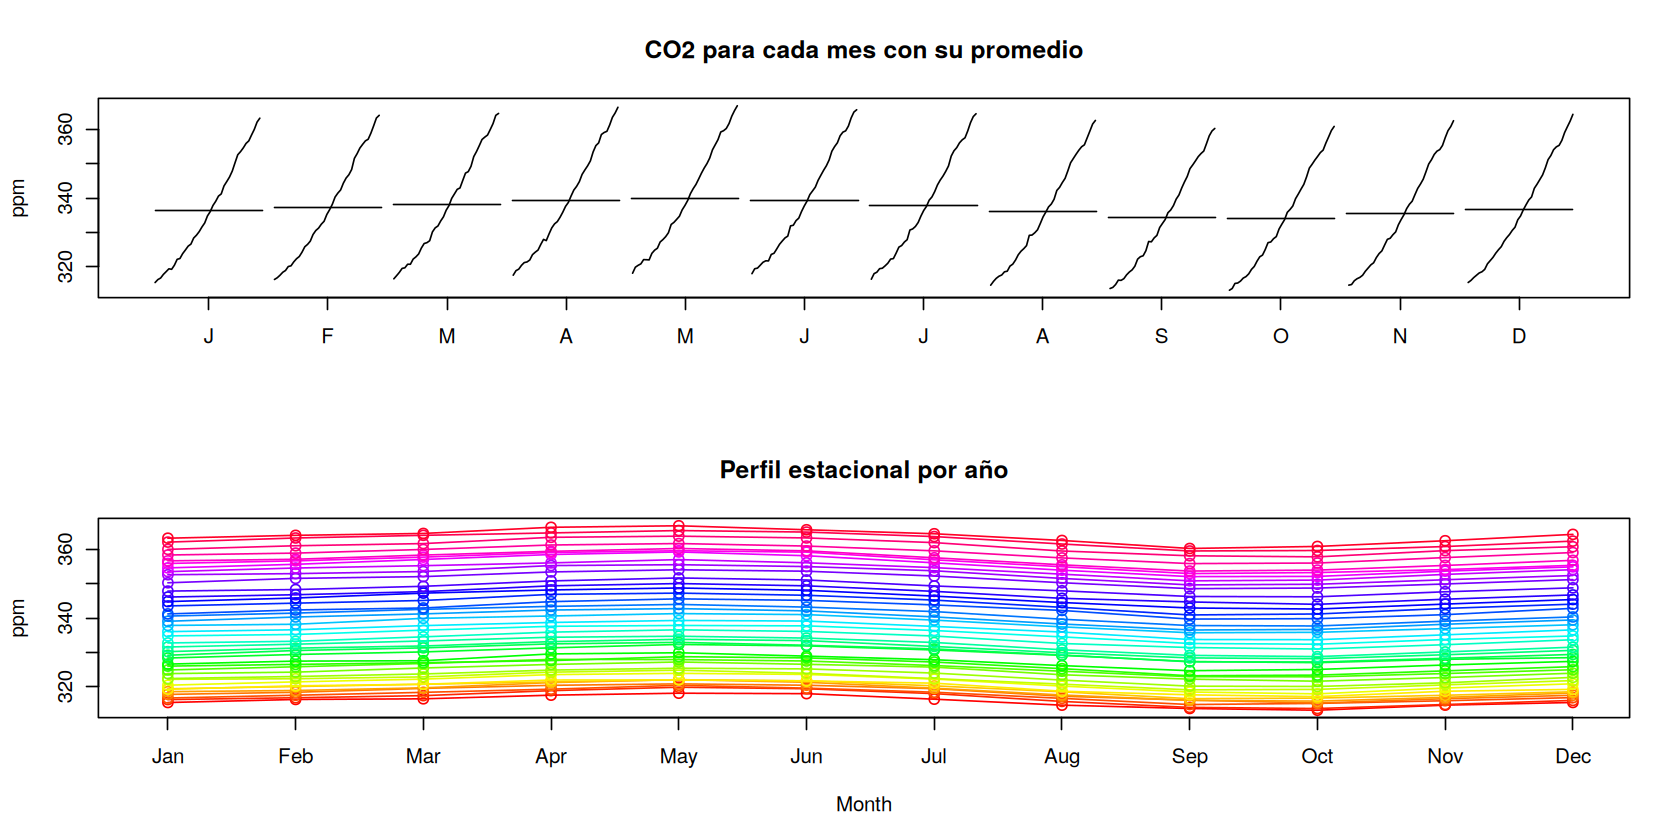

In [7]:
# Gráficos estacionales #
par(mfrow = c(2, 1))
monthplot(co2_ts, main = "CO2 para cada mes con su promedio", ylab = "ppm")
seasonplot(co2_ts, main = "Perfil estacional por año", ylab = "ppm", col = rainbow(39), year.labels = FALSE)
par(mfrow = c(1, 1))

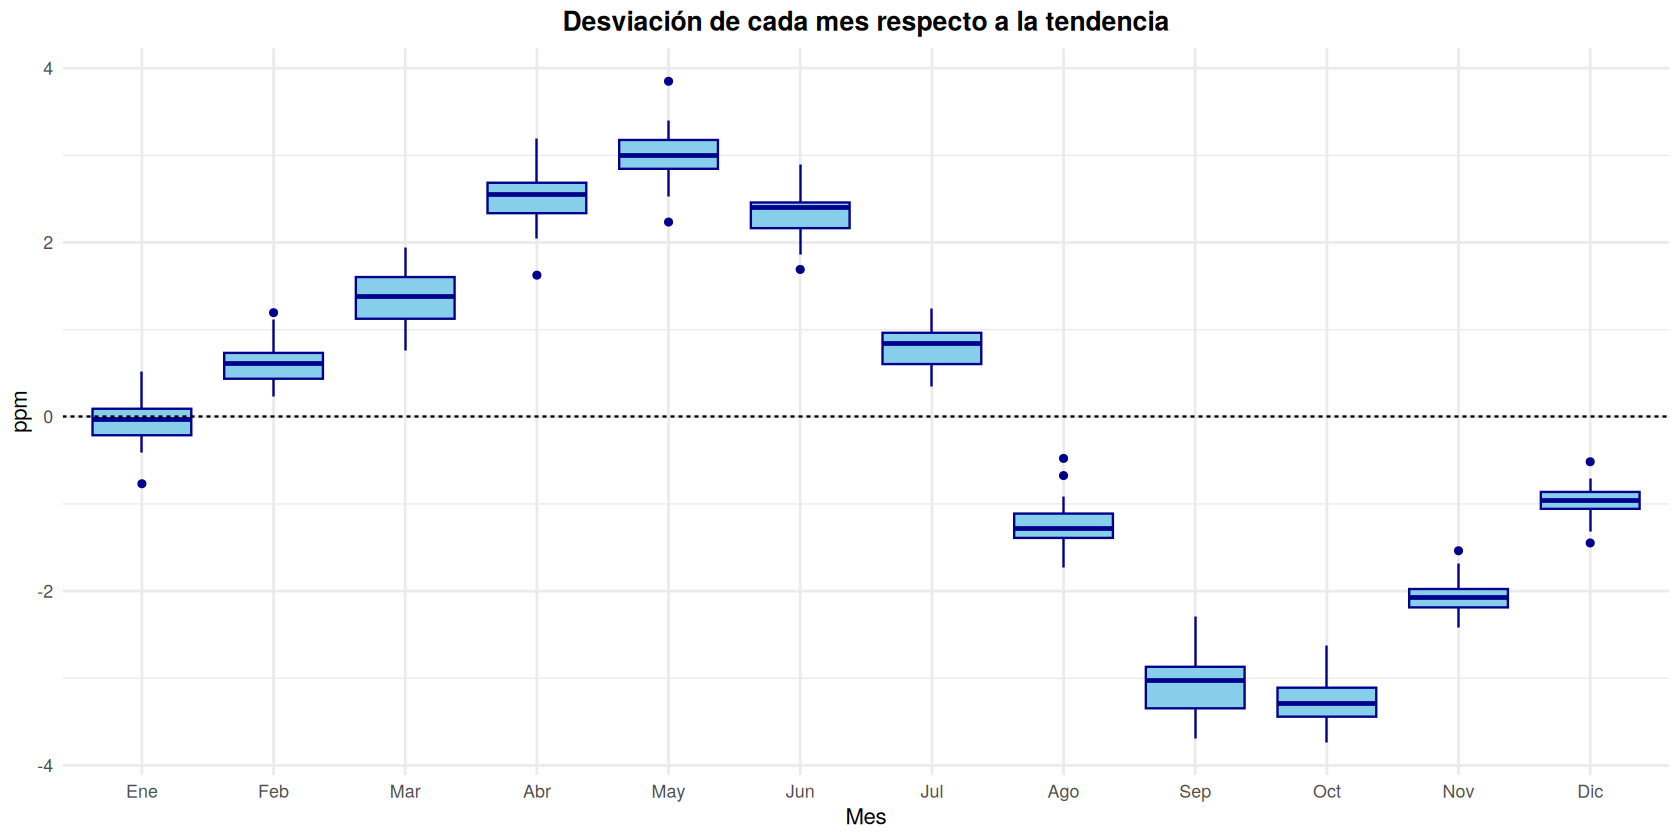

In [8]:
# Boxplot por mes: ¿qué meses son altos y cuáles bajos? #
meses <- c("Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic")
df_mes <- data.frame(Mes = factor(meses[cycle(co2_ts)], levels = meses),
                     # se quita la tendencia con la media móvil 2x12 para ver solo el efecto del mes
                     Desviacion = as.numeric(co2_ts - stats::filter(co2_ts, c(0.5, rep(1, 11), 0.5) / 12)))
ggplot(na.omit(df_mes), aes(x = Mes, y = Desviacion)) +
  geom_boxplot(fill = "skyblue", color = "darkblue") +
  geom_hline(yintercept = 0, linetype = "dashed") +
  labs(title = "Desviación de cada mes respecto a la tendencia", x = "Mes", y = "ppm") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5, face = "bold"))

<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

El pico del año está en **mayo** y el valle en **septiembre-octubre**, con una diferencia de unos 6 ppm entre los dos. Los meses se separan muy bien entre sí, así que la estacionalidad es fuerte y estable.

</div>

---
<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

<h1 align="center"><b>2. Suavizamiento con Medias Móviles </b></h1>

Una media móvil reemplaza cada dato por el promedio de sus vecinos. Si la ventana cubre exactamente un ciclo estacional, el efecto del mes se cancela y queda solo la tendencia. Con $S = 12$ (par) se usa la **media móvil centrada 2×12**:

$$\hat T_t = \frac{1}{24} y_{t-6} + \frac{1}{12}\left(y_{t-5} + \cdots + y_{t+5}\right) + \frac{1}{24} y_{t+6}$$

Comparamos ventanas cortas (3 y 5 meses), que todavía dejan pasar la estacionalidad, con la 2×12 y con una de 24 meses.

</div>

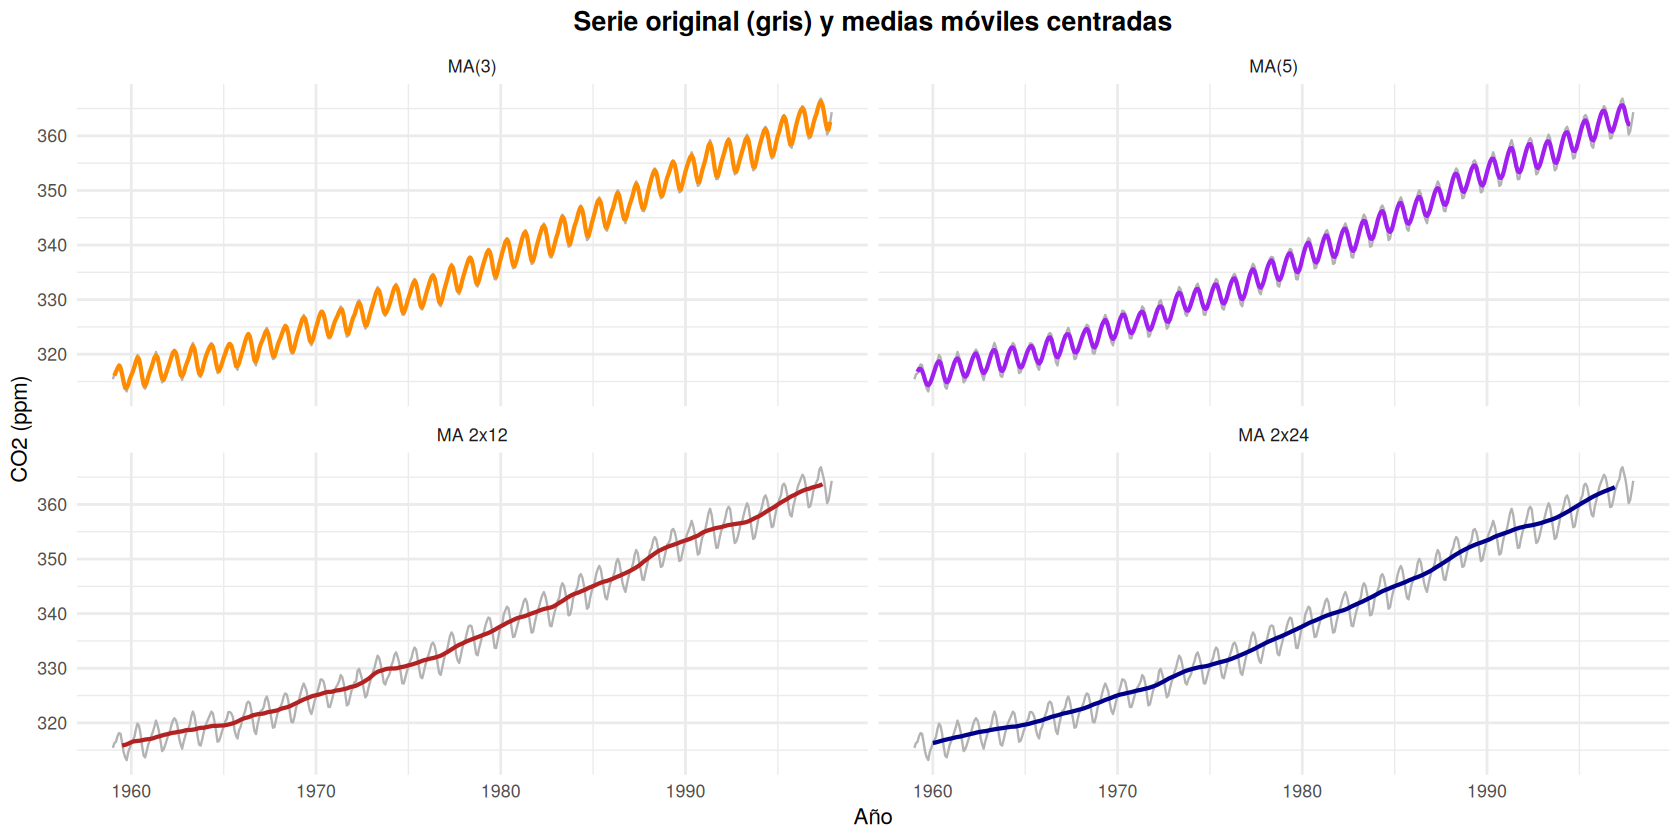

In [9]:
# Medias móviles centradas (sides = 2) #
ma3   <- stats::filter(co2_ts, rep(1/3, 3), sides = 2)
ma5   <- stats::filter(co2_ts, rep(1/5, 5), sides = 2)
ma2x12 <- stats::filter(co2_ts, c(0.5, rep(1, 11), 0.5) / 12, sides = 2)
ma24  <- stats::filter(co2_ts, c(0.5, rep(1, 23), 0.5) / 24, sides = 2)

tiempo <- as.numeric(time(co2_ts))
df_ma <- rbind(
  data.frame(Tiempo = tiempo, Valor = as.numeric(ma3),    Ventana = "MA(3)"),
  data.frame(Tiempo = tiempo, Valor = as.numeric(ma5),    Ventana = "MA(5)"),
  data.frame(Tiempo = tiempo, Valor = as.numeric(ma2x12), Ventana = "MA 2x12"),
  data.frame(Tiempo = tiempo, Valor = as.numeric(ma24),   Ventana = "MA 2x24"))
df_ma$Ventana <- factor(df_ma$Ventana, levels = c("MA(3)", "MA(5)", "MA 2x12", "MA 2x24"))

g_ma <- ggplot() +
  geom_line(data = df_co2, aes(x = Tiempo, y = CO2), color = "grey70") +
  geom_line(data = na.omit(df_ma), aes(x = Tiempo, y = Valor, color = Ventana), linewidth = 0.9) +
  facet_wrap(~ Ventana, ncol = 2) +
  scale_color_manual(values = c("darkorange", "purple", "firebrick", "darkblue")) +
  labs(title = "Serie original (gris) y medias móviles centradas", x = "Año", y = "CO2 (ppm)") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5, face = "bold"), legend.position = "none")
guardar(g_ma, "medias_moviles.png", alto = 7)
g_ma

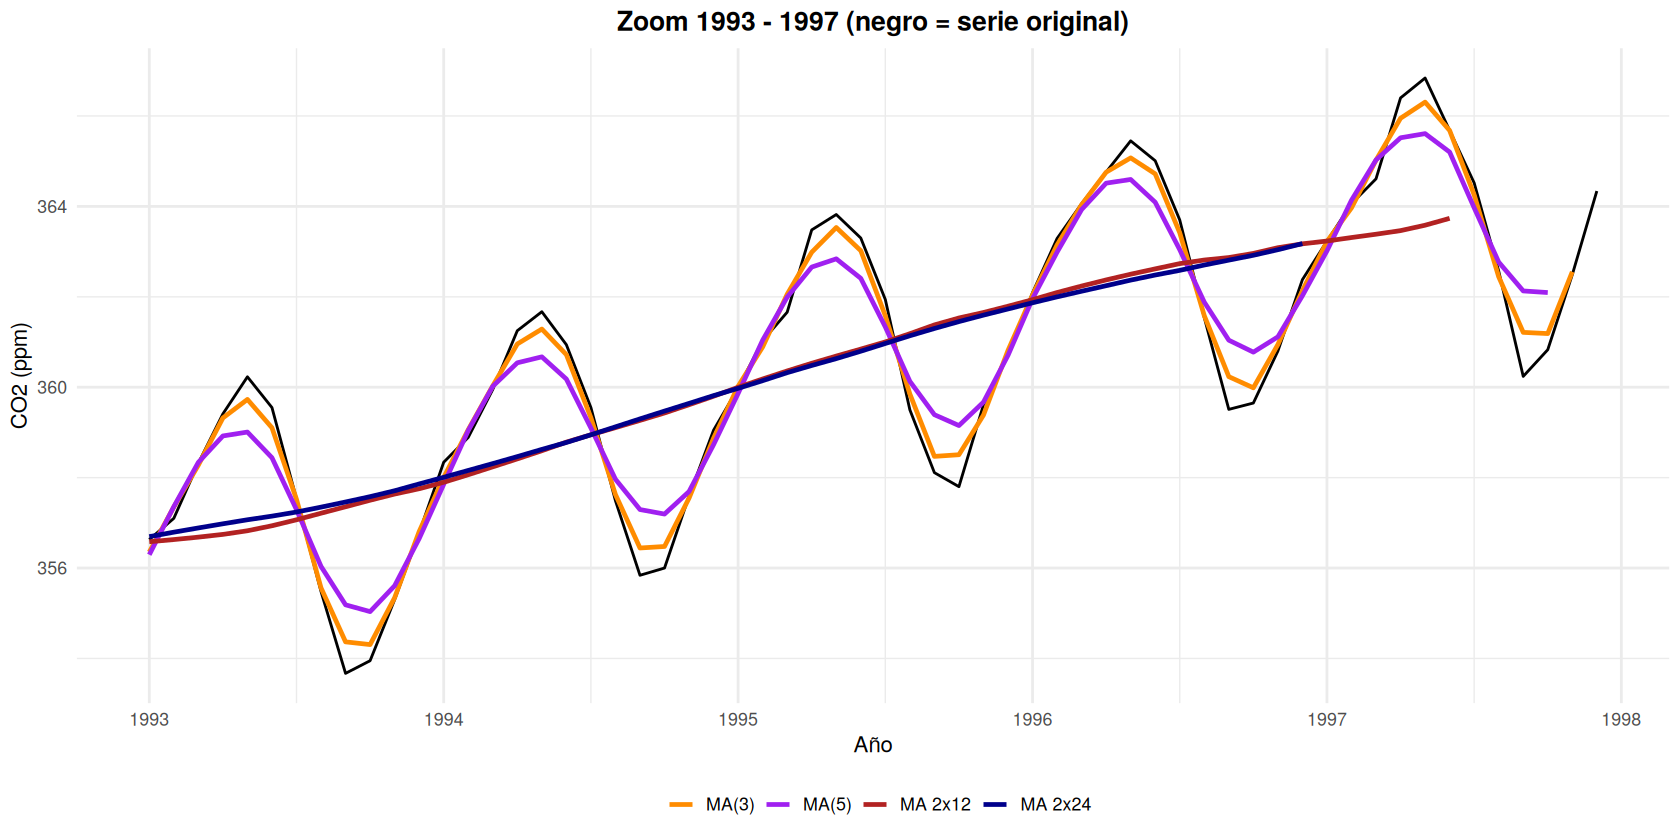

In [10]:
# Zoom a los últimos 5 años para ver la diferencia entre ventanas #
ggplot(subset(df_ma, Tiempo >= 1993), aes(x = Tiempo, y = Valor, color = Ventana)) +
  geom_line(data = subset(df_co2, Tiempo >= 1993), aes(x = Tiempo, y = CO2), color = "black",
            linewidth = 0.6, inherit.aes = FALSE) +
  geom_line(linewidth = 1) +
  scale_color_manual(values = c("darkorange", "purple", "firebrick", "darkblue")) +
  labs(title = "Zoom 1993 - 1997 (negro = serie original)", x = "Año", y = "CO2 (ppm)", color = "") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5, face = "bold"), legend.position = "bottom")

<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

Con ventanas de 3 y 5 meses la curva sigue subiendo y bajando dentro del año: esas ventanas son más cortas que el ciclo y no alcanzan a borrar la estacionalidad. La **2×12** ya deja una curva lisa, que es la **tendencia** de la serie, y la de 24 meses casi coincide con ella. Además la tendencia no es una recta, se curva hacia arriba, lo cual anticipa que la serie **no es estacionaria en media**.

</div>

In [11]:
# Pendiente de la tendencia: crecimiento anual promedio (ppm por año) en cada década #
crec <- diff(ma2x12, lag = 12)
df_crec <- data.frame(Decada = paste0(floor(tiempo[-(1:12)] / 10) * 10, "s"), Crecimiento = as.numeric(crec))
aggregate(Crecimiento ~ Decada, data = na.omit(df_crec), FUN = function(z) round(mean(z), 2))

Decada,Crecimiento
<chr>,<dbl>
1960s,0.85
1970s,1.23
1980s,1.60
1990s,1.39


<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

El crecimiento anual pasa de 0.85 ppm por año en los 60 a 1.60 ppm por año en los 80, es decir, la serie no solo sube sino que sube cada vez más rápido. En los 90 baja un poco (1.39 ppm por año), por la desaceleración de 1991 a 1993 que se suele asociar a la erupción del volcán Pinatubo. Así que la pendiente de la tendencia **no es fija**, y eso va a importar cuando decidamos cuántas diferencias tomar.

### **Descomposición clásica**

Usamos `decompose()`, que estima la tendencia justamente con la media móvil 2×12, luego promedia lo que sobra para cada mes (índice estacional) y deja el resto como componente aleatoria.

</div>

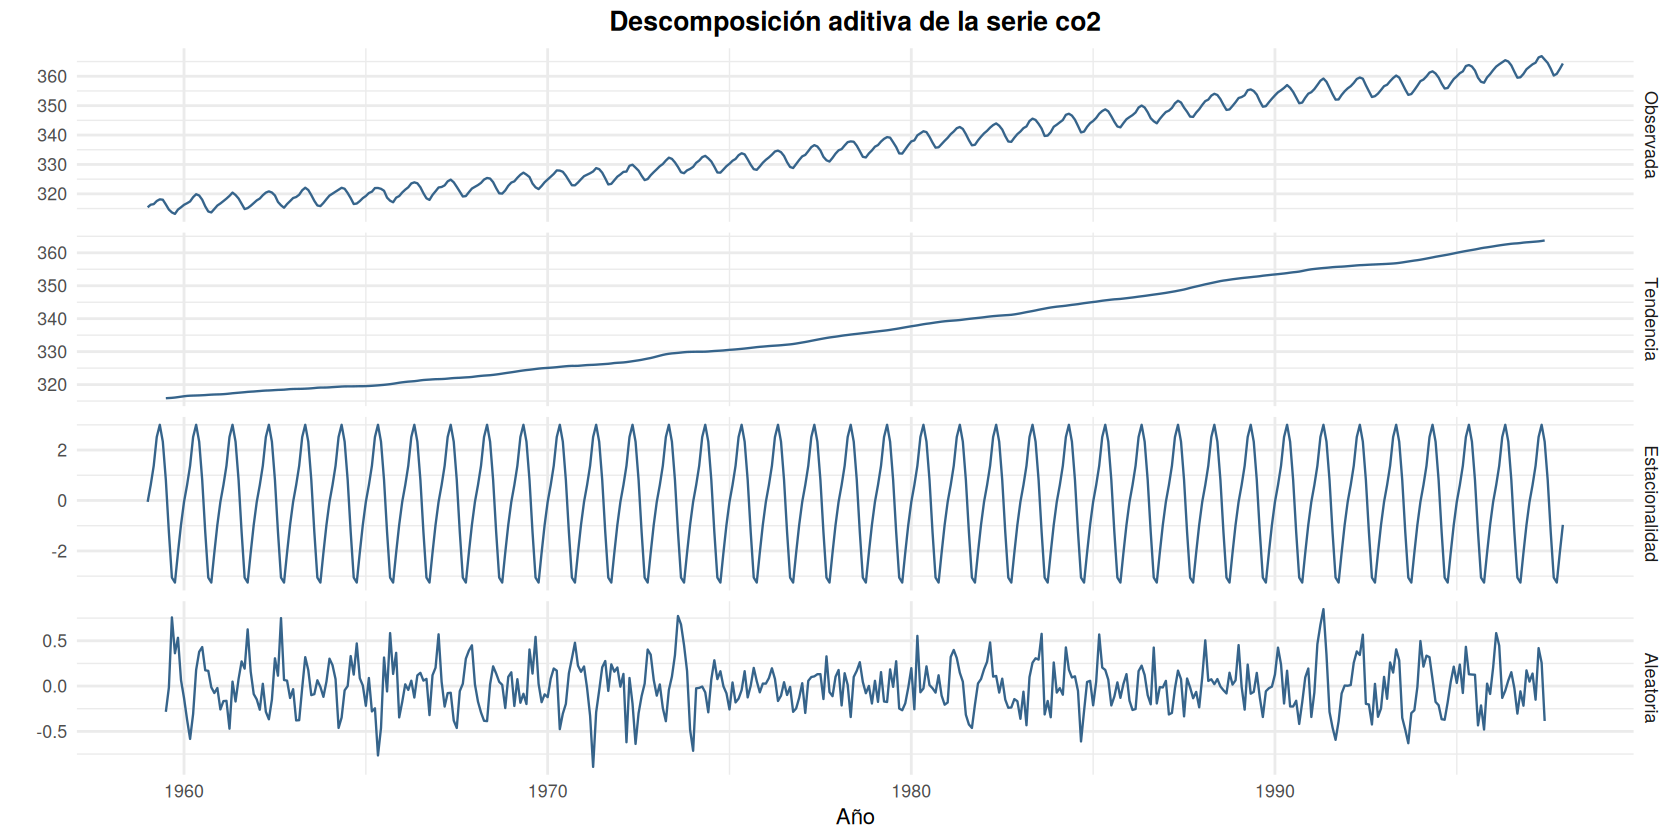

In [12]:
# Descomposición aditiva #
desc_adit <- decompose(co2_ts, type = "additive")
df_desc <- data.frame(
  Tiempo = rep(tiempo, 4),
  Valor = c(as.numeric(desc_adit$x), as.numeric(desc_adit$trend),
            as.numeric(desc_adit$seasonal), as.numeric(desc_adit$random)),
  Componente = factor(rep(c("Observada", "Tendencia", "Estacionalidad", "Aleatoria"), each = n),
                      levels = c("Observada", "Tendencia", "Estacionalidad", "Aleatoria")))
g_desc <- ggplot(na.omit(df_desc), aes(x = Tiempo, y = Valor)) +
  geom_line(color = "steelblue4") +
  facet_grid(Componente ~ ., scales = "free_y") +
  labs(title = "Descomposición aditiva de la serie co2", x = "Año", y = "") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5, face = "bold"))
guardar(g_desc, "descomposicion.png", alto = 8)
g_desc

In [13]:
# Índices estacionales aditivos (ppm sobre o bajo la tendencia) #
indices <- data.frame(Mes = meses, Indice_aditivo = round(desc_adit$figure, 3),
                      Indice_multiplicativo = round(decompose(co2_ts, type = "multiplicative")$figure, 5))
indices

Mes,Indice_aditivo,Indice_multiplicativo
<chr>,<dbl>,<dbl>
Ene,-0.054,0.99984
Feb,0.611,1.00181
Mar,1.376,1.00407
Abr,2.517,1.00745
May,3.000,1.00889
Jun,2.329,1.00691
Jul,0.813,1.00243
Ago,-1.251,0.99630
Sep,-3.055,0.99095


In [14]:
# ¿Cuánto explica cada componente? Varianza de la serie sin tendencia vs varianza del resto #
var_sin_tend <- var(na.omit(co2_ts - desc_adit$trend))
var_aleat    <- var(na.omit(desc_adit$random))
paste("Proporción de la variación (sin tendencia) explicada por la estacionalidad:",
      round(1 - var_aleat / var_sin_tend, 3))

[1] "Proporción de la variación (sin tendencia) explicada por la estacionalidad: 0.984"

<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

La componente aleatoria es muy pequeña (oscila en unas décimas de ppm) frente a la tendencia y la estacionalidad. Los índices multiplicativos son prácticamente $1 + \text{índice aditivo}/337$, así que las dos descomposiciones dicen lo mismo; nos quedamos con la **aditiva**, que es la más sencilla.

</div>

---
<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

<h1 align="center"><b>3. Homogeneidad de Varianzas </b></h1>

### **Prueba de Levene**

Igual que en el ejemplo de Amazon, partimos la serie en ventanas (aquí una por año, 39 ventanas) y probamos si la varianza es la misma en todas.

**$H_0: \sigma_1^2=\sigma_2^2=\cdots=\sigma_k^2$ (Homocedasticidad) $\hspace{0.4cm}$ $vs$ $\hspace{0.4cm}$ $H_1: \exists_{i,j}\ \sigma_i^2\neq \sigma_j^2$ (Heterocedasticidad)**

Si se rechaza $H_0$ habría que aplicar Box-Cox antes de modelar.

</div>

In [15]:
# División de la serie en ventanas anuales #
anio <- factor(floor(tiempo))
pl <- leveneTest(as.numeric(co2_ts) ~ anio)
print(pl)
if (pl$`Pr(>F)`[1] < 0.05) {
  print("Rechazamos H0: las varianzas son diferentes entre las ventanas.")
} else {
  print("No rechazamos H0: las varianzas son iguales entre las ventanas.")
}

Levene's Test for Homogeneity of Variance (center = median)
       Df F value Pr(>F)
group  38  0.2049      1
      429               


[1] "No rechazamos H0: las varianzas son iguales entre las ventanas."


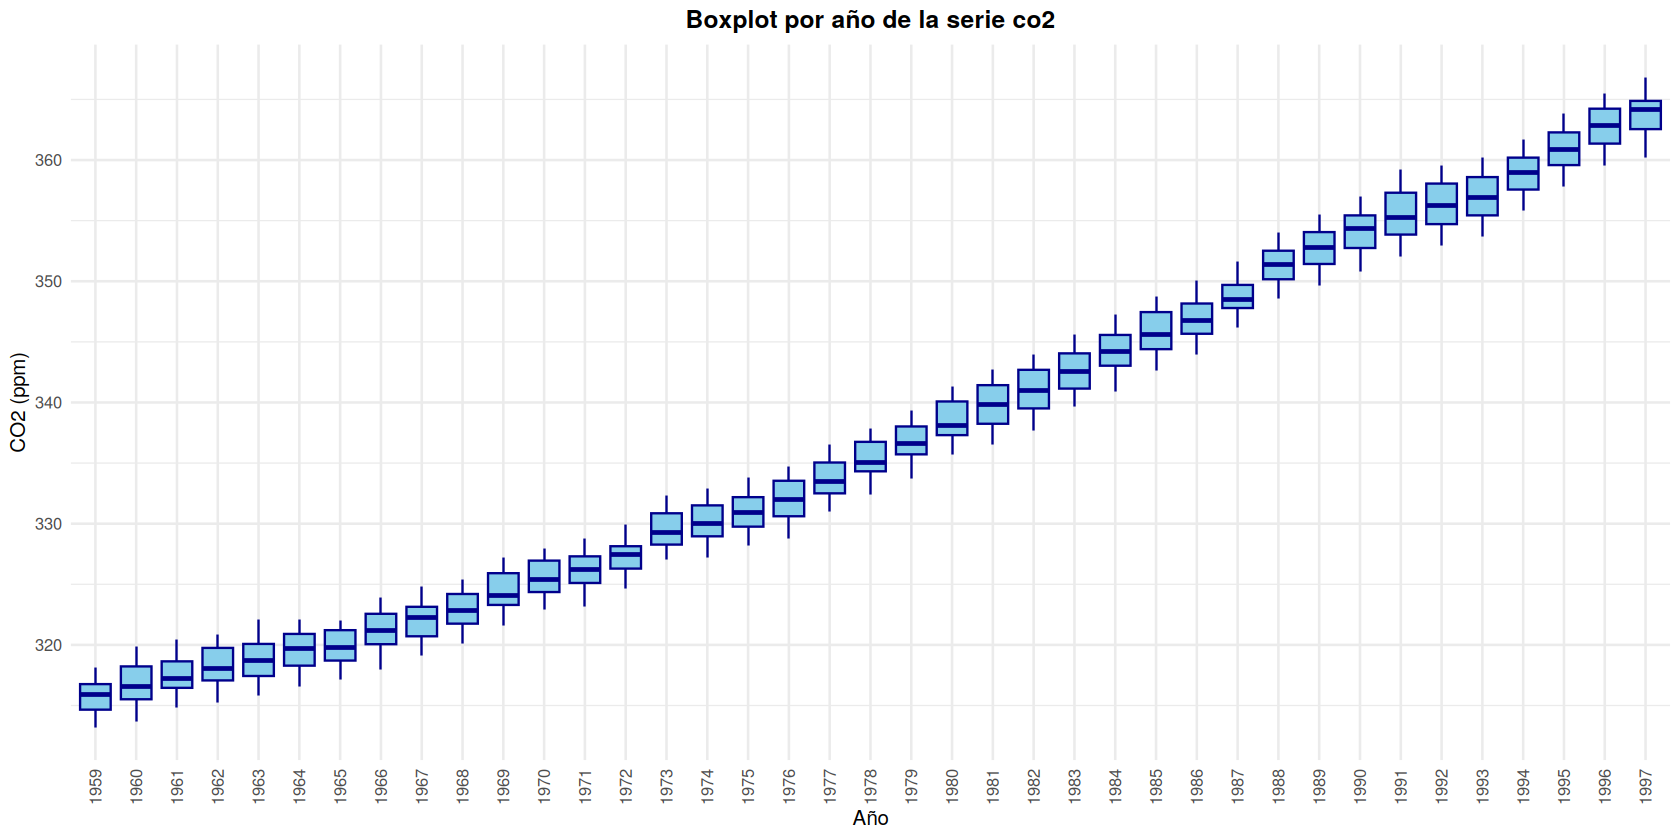

In [16]:
# Boxplot por año #
ggplot(data.frame(Anio = anio, CO2 = as.numeric(co2_ts)), aes(x = Anio, y = CO2)) +
  geom_boxplot(fill = "skyblue", color = "darkblue") +
  labs(title = "Boxplot por año de la serie co2", x = "Año", y = "CO2 (ppm)") +
  theme_minimal(base_size = 12) +
  theme(plot.title = element_text(hjust = 0.5, face = "bold"),
        axis.text.x = element_text(angle = 90, vjust = 0.5))

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),-0.065311226,0.495016599,-0.1319374,0.8957486358
Media,0.005931179,0.001467238,4.0424097,0.0002573079


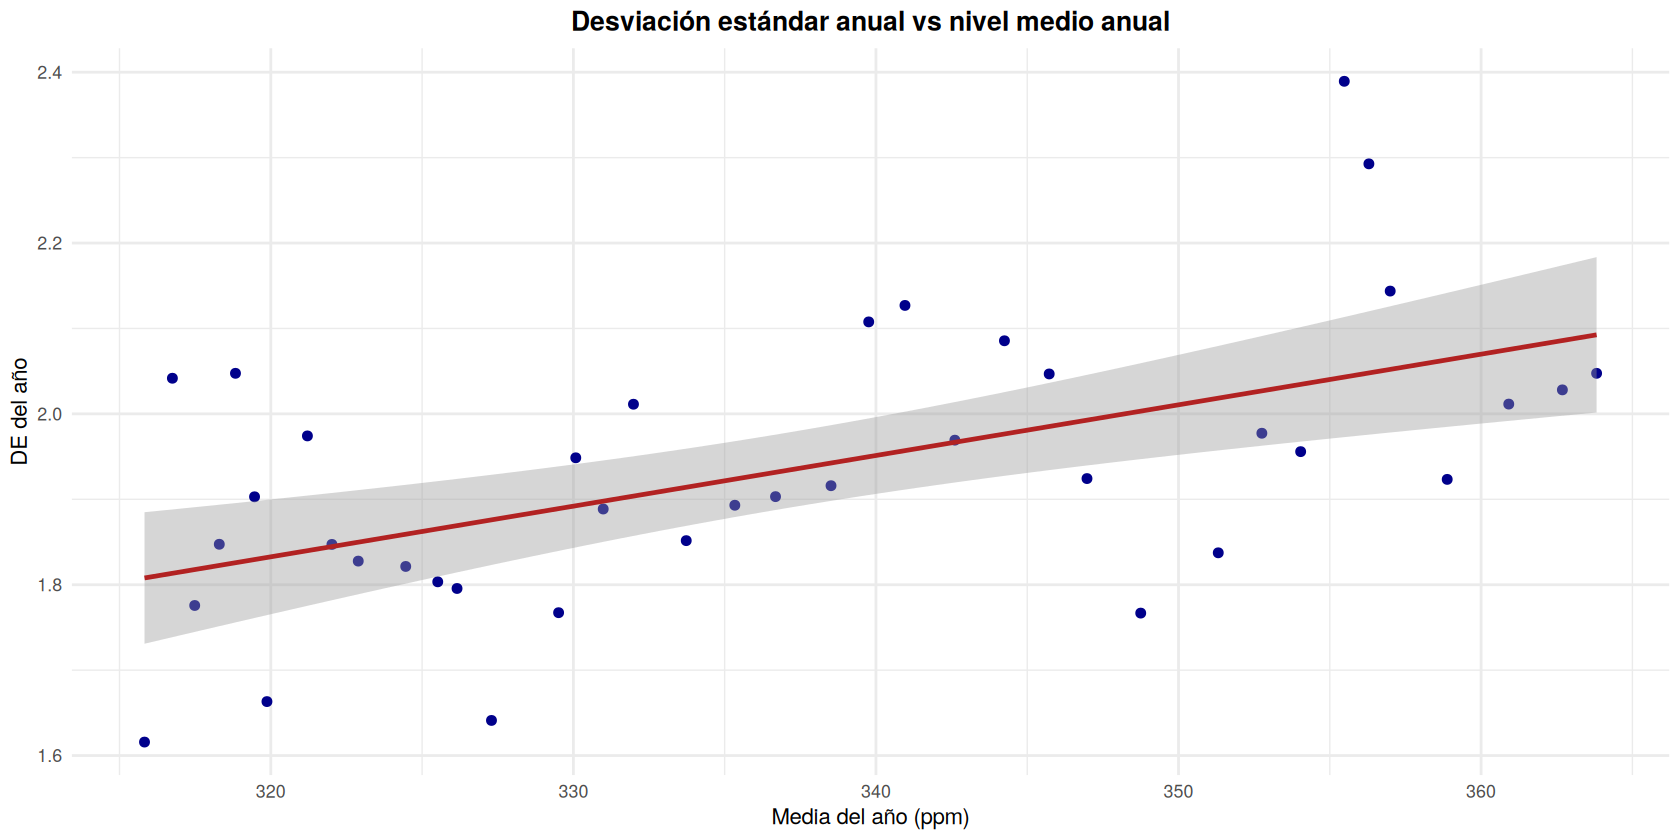

In [17]:
# La dispersión dentro de cada año no cambia con el nivel #
disp <- aggregate(as.numeric(co2_ts), by = list(Anio = floor(tiempo)),
                  FUN = function(z) c(Media = mean(z), DE = sd(z)))
disp <- data.frame(Anio = disp$Anio, Media = disp$x[, "Media"], DE = disp$x[, "DE"])
ggplot(disp, aes(x = Media, y = DE)) +
  geom_point(color = "darkblue", size = 2) +
  geom_smooth(method = "lm", formula = y ~ x, se = TRUE, color = "firebrick") +
  labs(title = "Desviación estándar anual vs nivel medio anual", x = "Media del año (ppm)", y = "DE del año") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5, face = "bold"))
summary(lm(DE ~ Media, data = disp))$coefficients

<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

### **Transformación de Box-Cox**

Siguiendo la metodología, antes de diferenciar revisamos si hace falta transformar. Miramos el $\lambda$ de Box-Cox con dos métodos: `powerTransform()` del paquete `car` y el método de Guerrero de `forecast`, que es el indicado para series de tiempo.

</div>

In [18]:
# Alternativa 1 (car) #
powerTransform(as.numeric(co2_ts))
# Alternativa 2 (forecast, método de Guerrero) #
paste("Lambda de Guerrero:", round(BoxCox.lambda(co2_ts), 4))

Estimated transformation parameter 
as.numeric(co2_ts) 
         -2.929357 

[1] "Lambda de Guerrero: -0.0343"

<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

**Conclusión sobre la varianza.** Levene no rechaza la homocedasticidad (p-valor muy cercano a 1). La regresión de la desviación estándar anual sobre el nivel sí da una pendiente significativa, pero minúscula: 0.006 ppm de desviación por cada ppm de nivel, o sea unas 0.3 ppm a lo largo de toda la serie, frente a una desviación anual cercana a 2 ppm. Eso refleja que la amplitud del ciclo estacional creció un poquito con los años, no un problema de varianza que haya que corregir. Sobre Box-Cox, los dos métodos dan valores muy distintos porque responden preguntas diferentes. `powerTransform()` de `car` ($\lambda \approx -2.93$) busca el $\lambda$ que vuelve normales los 468 valores tomados como datos sueltos; en una serie con tendencia eso no habla de la varianza, porque el histograma lo deforma la propia tendencia. El método de Guerrero ($\lambda \approx -0.03$), pensado para series de tiempo, busca igualar la dispersión a lo largo del tiempo y sugiere el logaritmo. Pero en el rango en que se mueve la serie (313 a 367 ppm) el logaritmo es prácticamente la misma serie: la correlación entre $\log(y_t)$ y $y_t$ es 0.9998. **No transformamos la serie** y trabajamos en ppm, que además es más fácil de interpretar. Esta es la diferencia principal con Air Passengers, donde sí hacía falta el logaritmo.

</div>

---
<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

<h1 align="center"><b>4. Pruebas de Estacionariedad y Diferenciación </b></h1>

Usamos dos pruebas con hipótesis contrarias, para que se respalden entre sí:

- **Dickey-Fuller aumentada (ADF):** $H_0$: tiene raíz unitaria (no estacionaria) $\hspace{0.3cm} vs \hspace{0.3cm}$ $H_a$: estacionaria.
- **KPSS:** $H_0$: estacionaria $\hspace{0.3cm} vs \hspace{0.3cm}$ $H_a$: tiene raíz unitaria.

</div>

In [19]:
# Función que resume ADF y KPSS para una serie #
pruebas_estac <- function(x, nombre) {
  adf  <- suppressWarnings(adf.test(x))
  kpss <- suppressWarnings(kpss.test(x, null = "Level"))
  data.frame(Serie = nombre,
             ADF_estadistico = round(adf$statistic, 3), ADF_pvalor = round(adf$p.value, 3),
             KPSS_estadistico = round(kpss$statistic, 3), KPSS_pvalor = round(kpss$p.value, 3),
             Conclusion = ifelse(adf$p.value < 0.05 & kpss$p.value > 0.05, "Estacionaria",
                          ifelse(adf$p.value >= 0.05 & kpss$p.value <= 0.05, "No estacionaria", "Pruebas en conflicto")),
             row.names = NULL)
}
pruebas_estac(co2_ts, "Original")

Serie,ADF_estadistico,ADF_pvalor,KPSS_estadistico,KPSS_pvalor,Conclusion
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Original,-2.83,0.227,7.817,0.01,No estacionaria


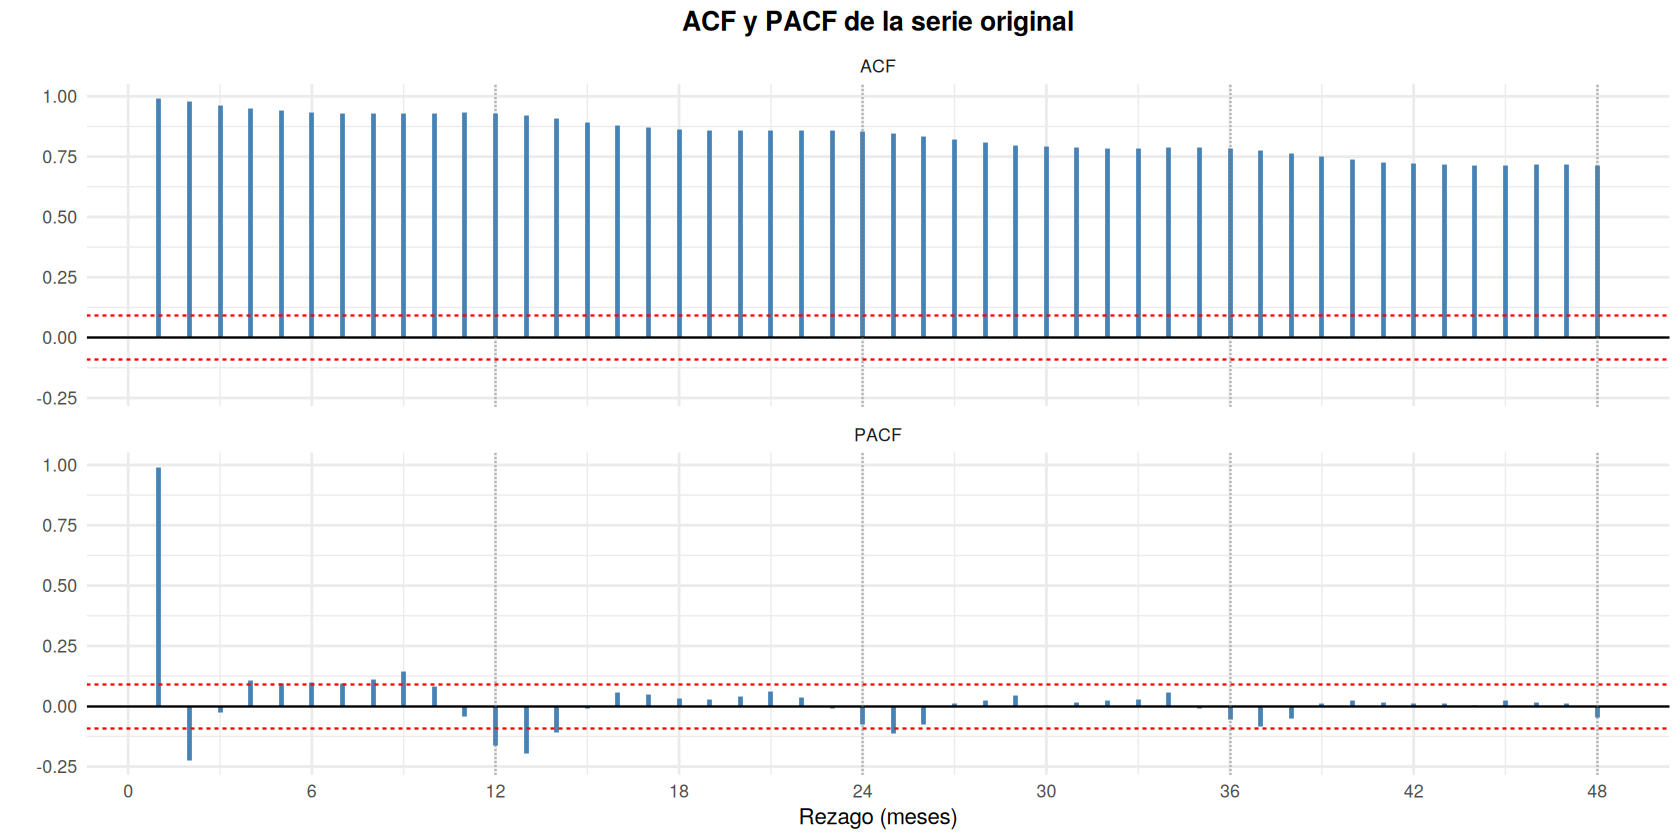

In [20]:
# ACF y PACF de la serie original #
graf_acf_pacf(co2_ts, lags = 48, titulo = "ACF y PACF de la serie original")

<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

La ADF no rechaza la raíz unitaria (p ≈ 0.23) y la KPSS rechaza la estacionariedad (p < 0.01): las dos coinciden en que **la serie original no es estacionaria**. La ACF lo confirma: decae lentísimo, casi linealmente, y además tiene ondulaciones cada 12 meses.

Para decidir cuántas diferencias hacen falta usamos también `ndiffs()` (diferencias ordinarias, basado en KPSS) y `nsdiffs()` (diferencias estacionales, basado en la fuerza de la estacionalidad).

</div>

In [21]:
paste("Diferencias ordinarias sugeridas, ndiffs():", ndiffs(co2_ts))
paste("Diferencias estacionales sugeridas, nsdiffs():", nsdiffs(co2_ts))
paste("Diferencias estacionales sugeridas después de (1-B), nsdiffs():", nsdiffs(diff(co2_ts)))

[1] "Diferencias ordinarias sugeridas, ndiffs(): 1"

[1] "Diferencias estacionales sugeridas, nsdiffs(): 1"

[1] "Diferencias estacionales sugeridas después de (1-B), nsdiffs(): 1"

In [22]:
# Las tres diferenciaciones posibles #
d1   <- diff(co2_ts)                 # (1 - B)
d12  <- diff(co2_ts, lag = 12)       # (1 - B^12)
d1d12 <- diff(diff(co2_ts), lag = 12) # (1 - B)(1 - B^12)

rbind(pruebas_estac(d1, "(1-B)"), pruebas_estac(d12, "(1-B^12)"), pruebas_estac(d1d12, "(1-B)(1-B^12)"))

Serie,ADF_estadistico,ADF_pvalor,KPSS_estadistico,KPSS_pvalor,Conclusion
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
(1-B),-30.380,0.01,0.012,0.10,Estacionaria
(1-B^12),-4.837,0.01,1.944,0.01,Pruebas en conflicto
(1-B)(1-B^12),-8.985,0.01,0.011,0.10,Estacionaria


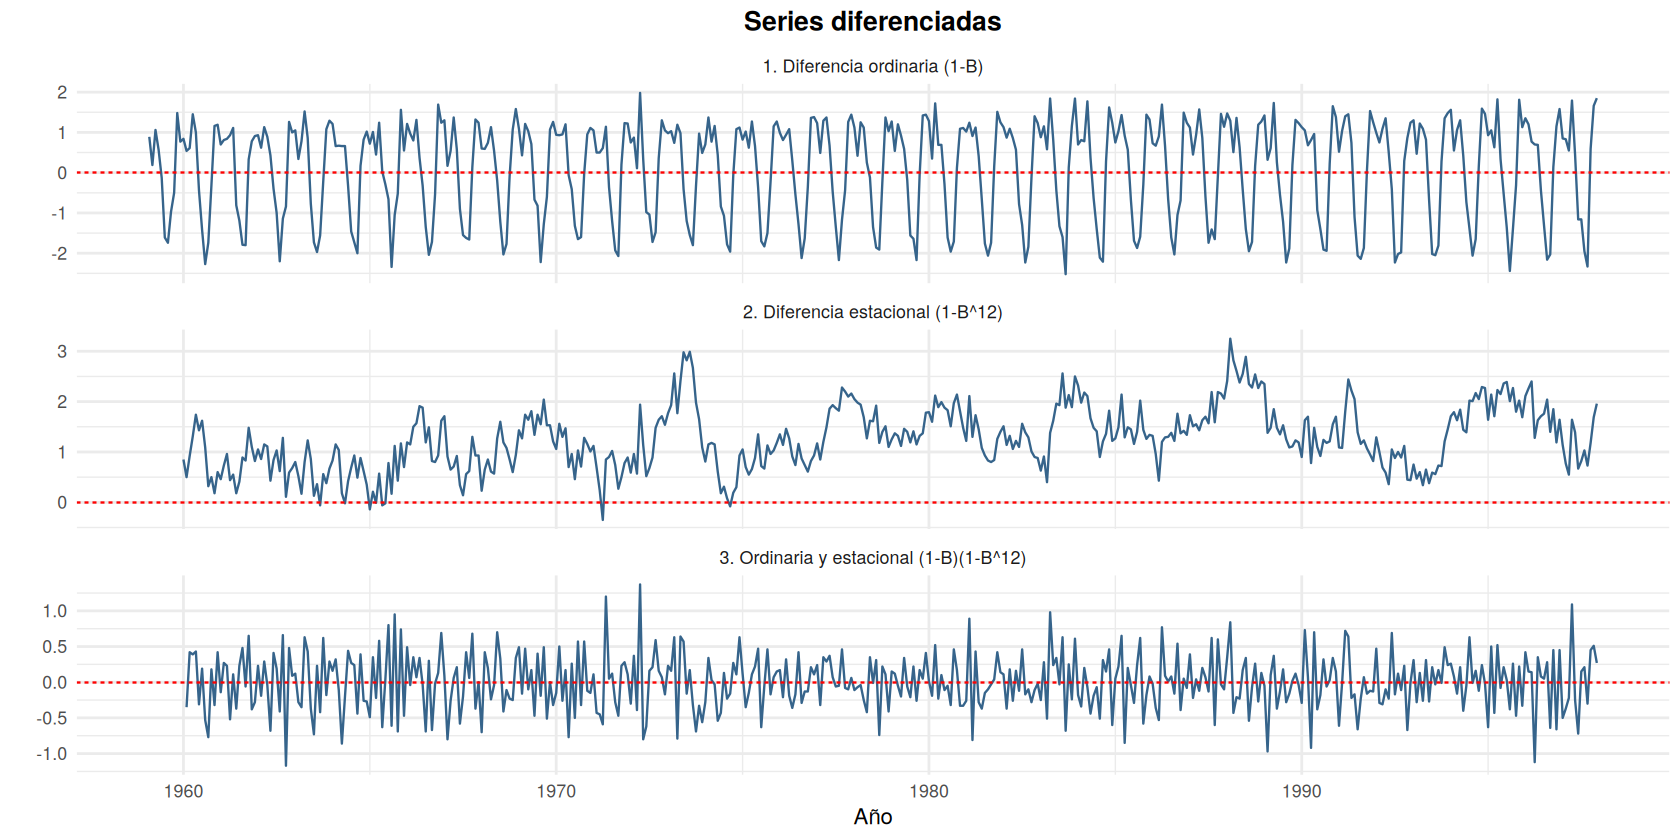

In [23]:
df_dif <- rbind(
  data.frame(Panel = "1. Diferencia ordinaria (1-B)", Tiempo = as.numeric(time(d1)), Valor = as.numeric(d1)),
  data.frame(Panel = "2. Diferencia estacional (1-B^12)", Tiempo = as.numeric(time(d12)), Valor = as.numeric(d12)),
  data.frame(Panel = "3. Ordinaria y estacional (1-B)(1-B^12)", Tiempo = as.numeric(time(d1d12)), Valor = as.numeric(d1d12)))
g_dif <- ggplot(df_dif, aes(x = Tiempo, y = Valor)) +
  geom_line(color = "steelblue4") +
  geom_hline(yintercept = 0, linetype = "dashed", color = "red") +
  facet_wrap(~ Panel, ncol = 1, scales = "free_y") +
  labs(title = "Series diferenciadas", x = "Año", y = "") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5, face = "bold"))
guardar(g_dif, "diferencias.png", alto = 8)
g_dif

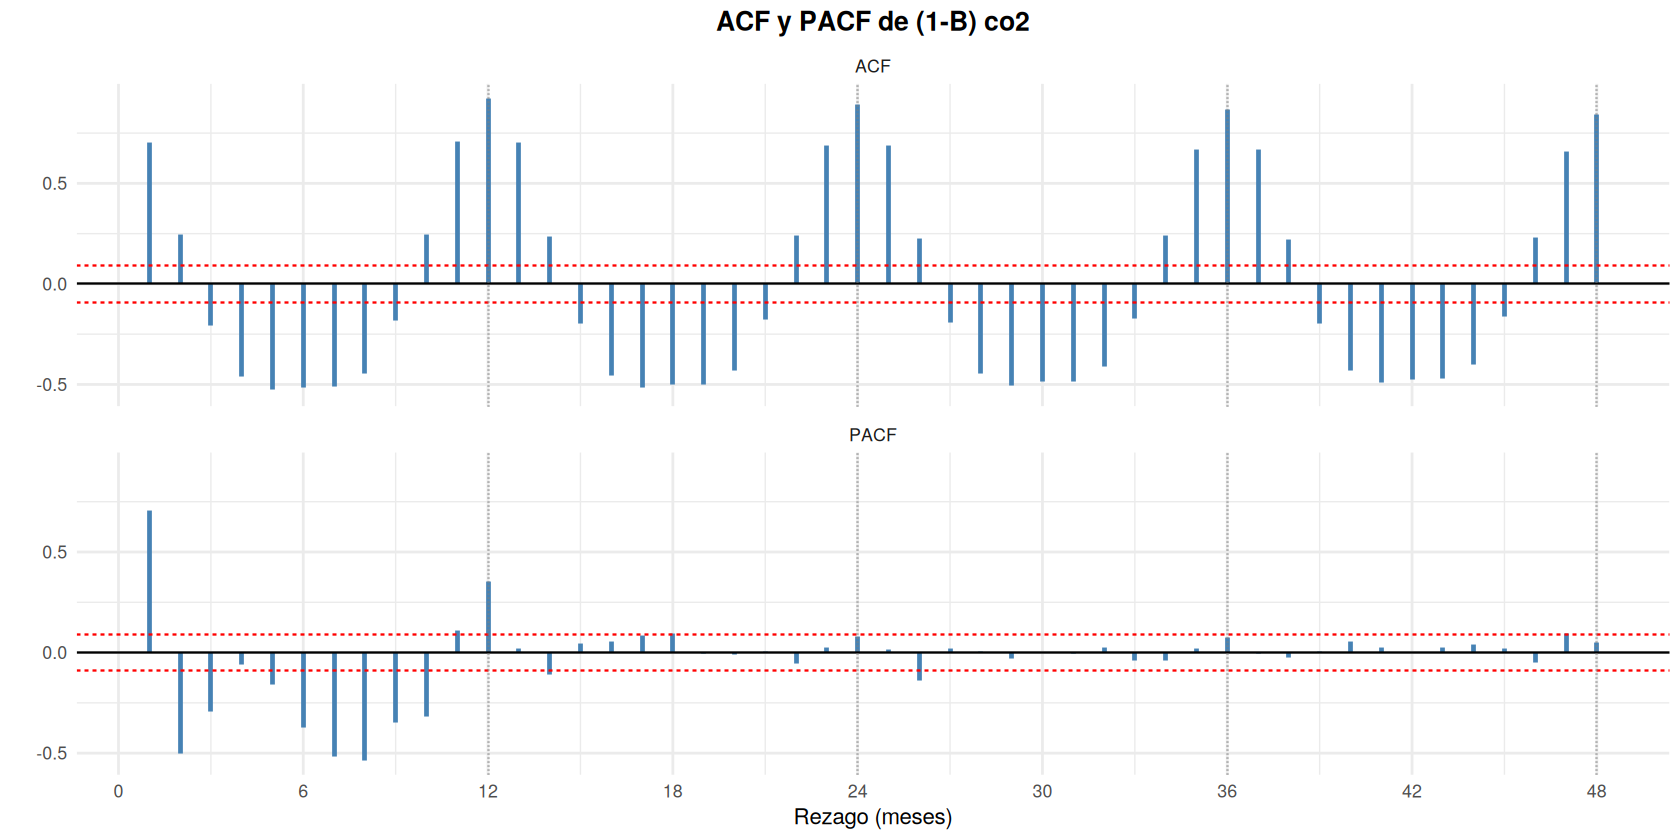

In [24]:
# ACF y PACF de la primera diferencia ordinaria #
graf_acf_pacf(d1, lags = 48, titulo = "ACF y PACF de (1-B) co2")

<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

Con solo la diferencia ordinaria la tendencia desaparece, pero la ACF tiene picos enormes y persistentes en 12, 24, 36 y 48: la **estacionalidad sigue ahí** y decae muy despacio, que es la señal de una raíz unitaria estacional. Las pruebas ADF y KPSS no detectan esto porque miran sobre todo los primeros rezagos.

</div>

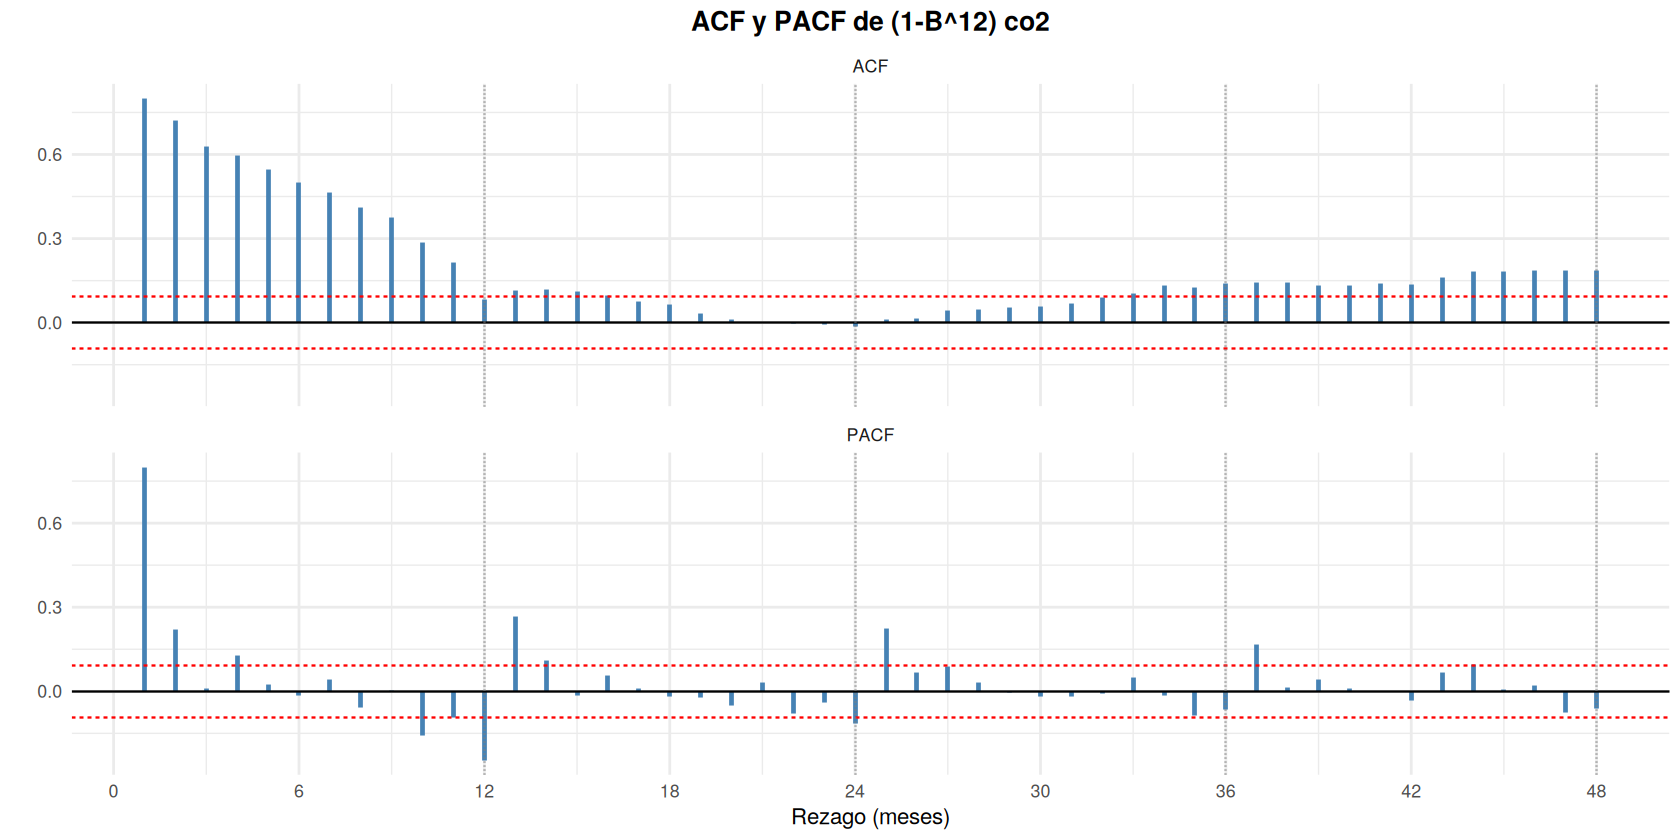

In [25]:
# ACF y PACF de la diferencia estacional sola #
graf_acf_pacf(d12, lags = 48, titulo = "ACF y PACF de (1-B^12) co2")

<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

Con solo la diferencia estacional, la ACF decae despacio desde valores altos en los primeros rezagos y la KPSS rechaza la estacionariedad: queda tendencia. Como la pendiente de la tendencia cambia con el tiempo (vimos que el crecimiento anual va de 0.8 a 1.5 ppm), una diferencia estacional sola no basta. Necesitamos las **dos diferencias**: $d = 1$ y $D = 1$.

</div>

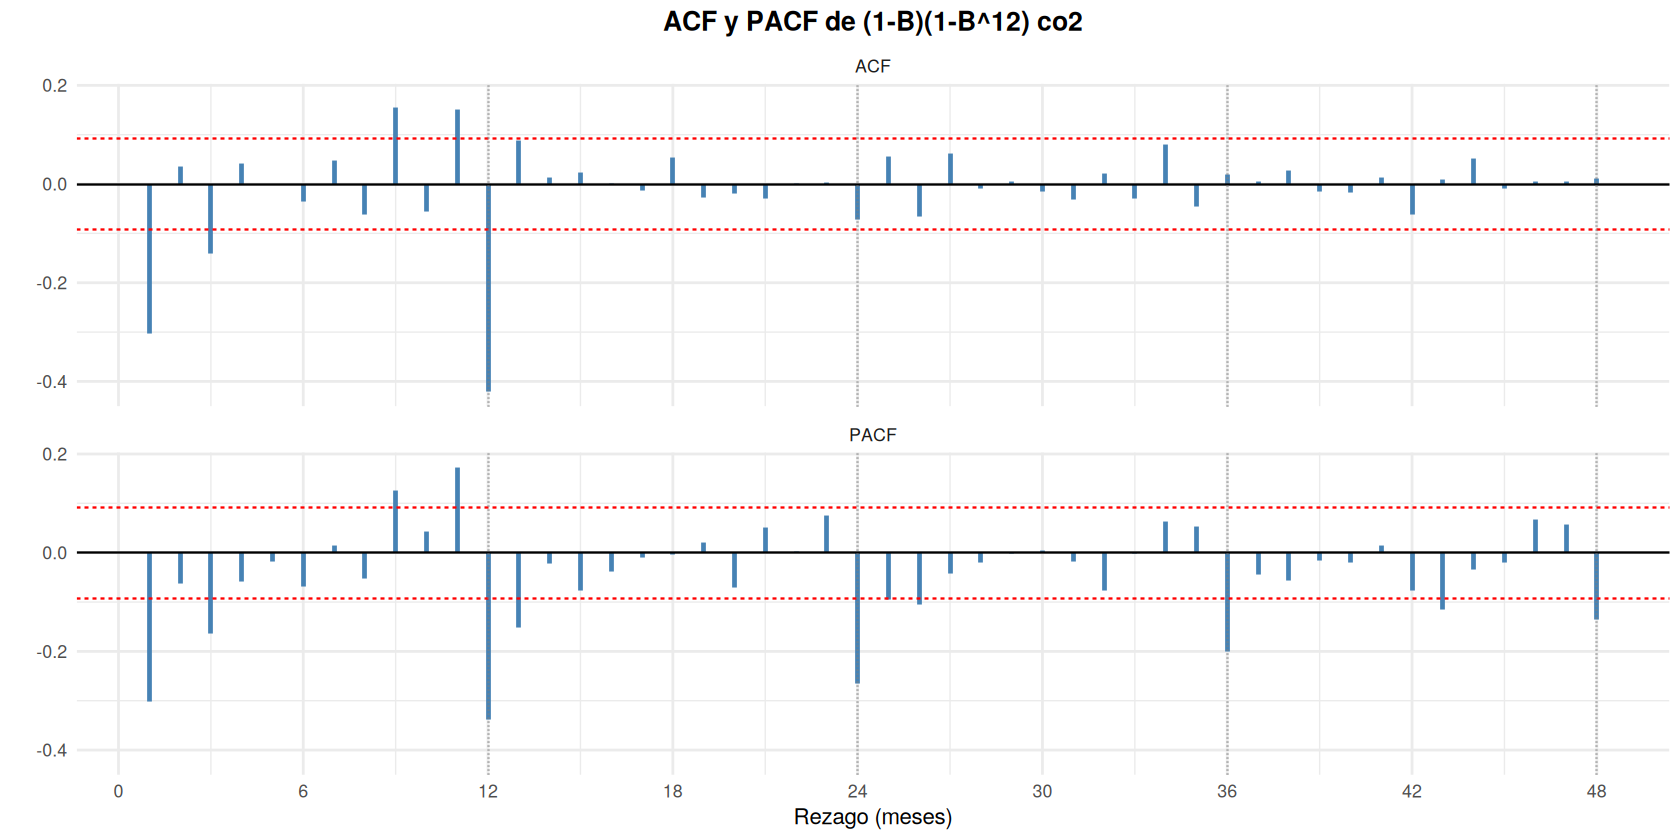

In [26]:
# ACF y PACF de (1-B)(1-B^12) #
g_acf_dd <- graf_acf_pacf(d1d12, lags = 48, titulo = "ACF y PACF de (1-B)(1-B^12) co2")
guardar(g_acf_dd, "acf_pacf_diferenciada.png", alto = 7)
g_acf_dd

In [27]:
# Valores de la ACF y la PACF en los rezagos clave #
acf_dd  <- acf(as.numeric(d1d12), lag.max = 36, plot = FALSE)$acf[-1]
pacf_dd <- pacf(as.numeric(d1d12), lag.max = 36, plot = FALSE)$acf[, 1, 1]
data.frame(Rezago = c(1, 2, 3, 11, 12, 13, 24, 36),
           ACF = round(acf_dd[c(1, 2, 3, 11, 12, 13, 24, 36)], 3),
           PACF = round(pacf_dd[c(1, 2, 3, 11, 12, 13, 24, 36)], 3),
           Banda = round(qnorm(0.975) / sqrt(length(d1d12)), 3))

Rezago,ACF,PACF,Banda
<dbl>,<dbl>,<dbl>,<dbl>
1,-0.302,-0.302,0.092
2,0.035,-0.062,0.092
3,-0.142,-0.164,0.092
11,0.151,0.173,0.092
12,-0.420,-0.338,0.092
13,0.089,-0.152,0.092
24,-0.071,-0.266,0.092
36,0.020,-0.201,0.092


---
<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

<h1 align="center"><b>5. Identificación </b></h1>

Leyendo la ACF y la PACF de $(1-B)(1-B^{12})\,co2_t$:

- **Parte regular:** la ACF tiene un pico negativo claro en el rezago 1 ($\approx -0.30$) y después prácticamente se corta (el rezago 3, con $-0.14$, apenas pasa la banda); la PACF decae en los primeros rezagos. Eso sugiere un **MA(1)** regular, $q = 1$.
- **Parte estacional:** la ACF tiene un pico negativo fuerte en el rezago 12 ($\approx -0.42$) y nada en 24 ni 36; la PACF decae en 12, 24 y 36 ($-0.34$, $-0.27$, $-0.20$). Eso sugiere un **MA(1) estacional**, $Q = 1$.
- Los pequeños picos en 11 y 13 son los "satélites" que aparecen cuando se multiplican los dos MA: $(1+\theta B)(1+\Theta B^{12})$ tiene un término en $B^{13}$.

## **Conclusión**: Hay evidencia de un $SARIMA(0,1,1)\times(0,1,1)_{12}$

Es el mismo modelo "de aerolíneas" que salió en Air Passengers, solo que aquí sin logaritmo:

$$(1-B)(1-B^{12})\,co2_t = (1+\theta B)(1+\Theta B^{12})\,a_t, \qquad a_t \sim RB(0, \sigma^2)$$

</div>

## **Identificación con Criterios de Información**

In [28]:
# Búsqueda de órdenes con d = 1 y D = 1, usando los criterios por observación del curso #
p <- 2; q <- 2; P <- 2; Q <- 2
d <- 1; D <- 1
combinaciones <- expand.grid(p = 0:p, q = 0:q, P = 0:P, Q = 0:Q)
ic_mod <- matrix(NA, nrow = nrow(combinaciones), ncol = 7,
                 dimnames = list(NULL, c("p", "q", "P", "Q", "AIC", "BIC", "AIC_R")))
for (k in 1:nrow(combinaciones)) {
  i <- combinaciones$p[k]; j <- combinaciones$q[k]; s <- combinaciones$P[k]; m <- combinaciones$Q[k]
  modelo <- tryCatch(Arima(co2_ts, order = c(i, d, j), seasonal = list(order = c(s, D, m), period = 12),
                           method = "CSS-ML"), error = function(e) NULL)
  ic_mod[k, 1:4] <- c(i, j, s, m)
  if (!is.null(modelo)) {
    numpar <- length(coef(modelo))
    T <- length(residuals(modelo))
    ic_mod[k, 5] <- -2 * (modelo$loglik / T) + (2 * numpar) / T        # AIC
    ic_mod[k, 6] <- -2 * (modelo$loglik / T) + (numpar * log(T)) / T   # BIC
    ic_mod[k, 7] <- modelo$aic                                          # AIC de R (sin dividir por T)
  }
}
Crit_Inf <- data.frame(ic_mod)
paste("Modelos ajustados:", sum(!is.na(Crit_Inf$AIC)), "de", nrow(Crit_Inf))

[1] "Modelos ajustados: 79 de 81"

In [29]:
# Ordenamiento por AIC de menor a mayor #
head(Crit_Inf[order(Crit_Inf$AIC), ], 8)

,p,q,P,Q,AIC,BIC,AIC_R
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
77,1,1,2,2,0.3647613,0.4179468,172.7083
80,1,2,2,2,0.3660717,0.4281215,173.3216
76,0,1,2,2,0.3664550,0.4107763,173.5009
81,2,2,2,2,0.3672569,0.4381709,173.8762
79,0,2,2,2,0.3675904,0.4207759,174.0323
33,2,1,0,1,0.3757004,0.4111574,177.8278
32,1,1,0,1,0.3762119,0.4028047,178.0672
31,0,1,0,1,0.3764011,0.3941296,178.1557


In [30]:
# Ordenamiento por BIC de menor a mayor #
head(Crit_Inf[order(Crit_Inf$BIC), ], 8)

,p,q,P,Q,AIC,BIC,AIC_R
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
31,0,1,0,1,0.3764011,0.3941296,178.1557
32,1,1,0,1,0.3762119,0.4028047,178.0672
34,0,2,0,1,0.3784025,0.4049953,179.0924
58,0,1,0,2,0.3800871,0.4066798,179.8808
40,0,1,1,1,0.3801784,0.4067712,179.9235
29,1,0,0,1,0.3892772,0.4070057,184.1817
76,0,1,2,2,0.3664550,0.4107763,173.5009
33,2,1,0,1,0.3757004,0.4111574,177.8278


<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

El **BIC** escoge exactamente el $SARIMA(0,1,1)\times(0,1,1)_{12}$ que propusimos con la ACF y la PACF. El **AIC**, que castiga menos los parámetros, prefiere modelos más grandes como el $SARIMA(1,1,1)\times(2,1,2)_{12}$, con 6 parámetros. Vamos a ver también qué dice `auto.arima()`.

</div>

### **Usando la función auto.arima()**

In [31]:
mod_auto <- auto.arima(co2_ts)
mod_auto

Series: co2_ts 
ARIMA(1,1,1)(1,1,2)[12] 

Coefficients:
         ar1      ma1     sar1     sma1     sma2
      0.2569  -0.5847  -0.5489  -0.2620  -0.5123
s.e.  0.1406   0.1204   0.5882   0.5703   0.4821

sigma^2 = 0.08576:  log likelihood = -84.39
AIC=180.78   AICc=180.97   BIC=205.5

<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

`auto.arima()` escoge un $SARIMA(1,1,1)\times(1,1,2)_{12}$, también más grande que el nuestro. Llevamos a la etapa de estimación **cuatro modelos candidatos**:

| Modelo | Especificación | Origen |
|---|---|---|
| **M1** | $SARIMA(0,1,1)\times(0,1,1)_{12}$ | ACF/PACF y mínimo BIC |
| **M2** | $SARIMA(1,1,1)\times(0,1,1)_{12}$ | Segundo por BIC, AIC casi igual a M1 |
| **M3** | $SARIMA(1,1,1)\times(1,1,2)_{12}$ | `auto.arima()` |
| **M4** | $SARIMA(1,1,1)\times(2,1,2)_{12}$ | Mínimo AIC |

</div>

---
<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

<h1 align="center"><b>6. Estimación </b></h1>

</div>

In [32]:
# Especificaciones de los modelos candidatos #
especificaciones <- list(
  M1 = list(order = c(0, 1, 1), seasonal = c(0, 1, 1)),
  M2 = list(order = c(1, 1, 1), seasonal = c(0, 1, 1)),
  M3 = list(order = c(1, 1, 1), seasonal = c(1, 1, 2)),
  M4 = list(order = c(1, 1, 1), seasonal = c(2, 1, 2)))
nombres_mod <- c(M1 = "SARIMA(0,1,1)(0,1,1)12", M2 = "SARIMA(1,1,1)(0,1,1)12",
                 M3 = "SARIMA(1,1,1)(1,1,2)12", M4 = "SARIMA(1,1,1)(2,1,2)12")

ajustar <- function(y, esp) {
  tryCatch(Arima(y, order = esp$order, seasonal = list(order = esp$seasonal, period = 12), method = "CSS-ML"),
           error = function(e) Arima(y, order = esp$order, seasonal = list(order = esp$seasonal, period = 12), method = "ML"))
}
modelos <- lapply(especificaciones, function(e) ajustar(co2_ts, e))

### **Modelo 1: estimación con la función arima() (ML condicional, exacta y CSS-ML)**

In [33]:
# Estimación ML condicional #
(mod_css <- arima(co2_ts, order = c(0, 1, 1), seasonal = list(order = c(0, 1, 1), period = 12), method = "CSS"))
# Estimación ML exacta #
(mod_ml <- arima(co2_ts, order = c(0, 1, 1), seasonal = list(order = c(0, 1, 1), period = 12), method = "ML"))
# Estimación ML exacta con valores iniciales de la condicional #
(mod <- arima(co2_ts, order = c(0, 1, 1), seasonal = list(order = c(0, 1, 1), period = 12), method = "CSS-ML"))


Call:
arima(x = co2_ts, order = c(0, 1, 1), seasonal = list(order = c(0, 1, 1), period = 12), 
    method = "CSS")

Coefficients:
          ma1     sma1
      -0.3643  -0.7927
s.e.   0.0481   0.0269

sigma^2 estimated as 0.08887:  part log likelihood = -94.94


Call:
arima(x = co2_ts, order = c(0, 1, 1), seasonal = list(order = c(0, 1, 1), period = 12), 
    method = "ML")

Coefficients:
          ma1     sma1
      -0.3501  -0.8507
s.e.   0.0496   0.0256

sigma^2 estimated as 0.0826:  log likelihood = -86.08,  aic = 178.16


Call:
arima(x = co2_ts, order = c(0, 1, 1), seasonal = list(order = c(0, 1, 1), period = 12), 
    method = "CSS-ML")

Coefficients:
          ma1     sma1
      -0.3501  -0.8506
s.e.   0.0496   0.0257

sigma^2 estimated as 0.0826:  log likelihood = -86.08,  aic = 178.16

### **Modelo 1: usando la función sarima()**

In [34]:
mod1 <- sarima(co2_ts, p = 0, d = 1, q = 1, P = 0, D = 1, Q = 1, S = 12, details = FALSE)

<><><><><><><><><><><><><><>
 
Coefficients: 
     Estimate     SE  t.value p.value
ma1   -0.3501 0.0496  -7.0529       0
sma1  -0.8506 0.0257 -33.1505       0

sigma^2 estimated as 0.08260341 on 453 degrees of freedom 
 
AIC = 0.391551  AICc = 0.3916094  BIC = 0.4187178 
 


In [35]:
# Significancia de las estimaciones #
mod1$t.table
# Criterios de información (AIC, AICc, BIC) #
mod1$ICs

,Estimate,SE,t.value,p.value
ma1,-0.3501,0.0496,-7.0529,0
sma1,-0.8506,0.0257,-33.1505,0


AIC      AICc       BIC 
0.3915510 0.3916094 0.4187178

<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

Los dos parámetros de M1 son muy significativos: $\hat\theta \approx -0.35$ y $\hat\Theta \approx -0.85$. ML exacta y CSS-ML coinciden; la condicional (CSS) da valores parecidos ($-0.36$ y $-0.79$) porque no aprovecha bien las primeras observaciones. El modelo estimado queda:

$$(1-B)(1-B^{12})\,co2_t = (1 - 0.35B)(1 - 0.85B^{12})\,a_t, \qquad \hat\sigma \approx 0.29 \text{ ppm}$$

Ambos coeficientes MA están dentro del círculo unitario en valor absoluto, así que **el modelo es invertible**. No hay parte AR, entonces la estacionariedad la garantiza la diferenciación.

</div>

### **Significancia de los cuatro candidatos**

In [36]:
for (m in names(modelos)) {
  cat("\n=====", m, ":", nombres_mod[m], "=====\n")
  print(coeftest(modelos[[m]]))
}


===== M1 : SARIMA(0,1,1)(0,1,1)12 =====

z test of coefficients:

      Estimate Std. Error  z value  Pr(>|z|)    
ma1  -0.350079   0.049637  -7.0529 1.753e-12 ***
sma1 -0.850587   0.025658 -33.1505 < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


===== M2 : SARIMA(1,1,1)(0,1,1)12 =====

z test of coefficients:

      Estimate Std. Error  z value  Pr(>|z|)    
ar1   0.239889   0.143040   1.6771   0.09353 .  
ma1  -0.570987   0.123679  -4.6167 3.899e-06 ***
sma1 -0.851554   0.025582 -33.2875 < 2.2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


===== M3 : SARIMA(1,1,1)(1,1,2)12 =====

z test of coefficients:

     Estimate Std. Error z value  Pr(>|z|)    
ar1   0.25690    0.14059  1.8273   0.06765 .  
ma1  -0.58472    0.12035 -4.8585 1.183e-06 ***
sar1 -0.54894    0.58821 -0.9332   0.35070    
sma1 -0.26203    0.57035 -0.4594   0.64593    
sma2 -0.51231    0.48210 -1.0627   0.28793    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’

In [37]:
# Raíces de los polinomios: módulo de las raíces (deben estar por fuera del círculo unitario, > 1) #
raices <- function(mod) {
  cf <- coef(mod)
  pol <- function(pref, signo) {
    c_ <- cf[grepl(paste0("^", pref, "[0-9]"), names(cf))]
    if (length(c_) == 0) return(NA)
    paste(round(Mod(polyroot(c(1, signo * c_))), 3), collapse = ", ")
  }
  data.frame(AR = pol("ar", -1), MA = pol("ma", 1), SAR = pol("sar", -1), SMA = pol("sma", 1))
}
tab_raices <- do.call(rbind, lapply(modelos, raices))
cbind(Modelo = nombres_mod, tab_raices)

,Modelo,AR,MA,SAR,SMA
,<chr>,<chr>,<chr>,<chr>,<chr>
M1,"SARIMA(0,1,1)(0,1,1)12",NA,2.856,NA,1.176
M2,"SARIMA(1,1,1)(0,1,1)12",4.169,1.751,NA,1.174
M3,"SARIMA(1,1,1)(1,1,2)12",3.893,1.71,1.822,"1.165, 1.676"
M4,"SARIMA(1,1,1)(2,1,2)12",3.777,1.682,"1.259, 5.952","1.08, 1.08"


<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

**Observaciones sobre los candidatos grandes:**

- **M2:** el $\phi_1$ adicional no es significativo al 5 % (p ≈ 0.09), y el MA regular cambia de $-0.35$ a $-0.57$ para compensar. El AR y el MA se están "repartiendo" el mismo efecto.
- **M3 (`auto.arima`):** ninguno de los tres parámetros estacionales es significativo y sus errores estándar son enormes (del mismo tamaño que los coeficientes). Es un modelo sobreparametrizado.
- **M4 (mínimo AIC):** todos sus coeficientes salen significativos, pero el polinomio MA estacional tiene una raíz doble en 1.08, casi encima del círculo unitario (el modelo está al borde de no ser invertible), y el AR estacional, con $\Phi_1 \approx 0.96$, se dedica a compensar ese efecto. Los dos polinomios estacionales se contrarrestan, algo parecido a lo que pasó con el ARFIMA(2,d,2) del seminario. Mejora el ajuste dentro de muestra, pero es un modelo frágil.

</div>

In [38]:
# Tabla resumen de criterios de información (versión del curso, por observación) #
resumen_ic <- do.call(rbind, lapply(names(modelos), function(m) {
  mo <- modelos[[m]]; T <- length(residuals(mo)); k <- length(coef(mo))
  data.frame(Modelo = m, Especificacion = nombres_mod[m], Parametros = k,
             sigma = round(sqrt(mo$sigma2), 4), LogLik = round(mo$loglik, 2),
             AIC = round(-2 * mo$loglik / T + 2 * k / T, 4),
             BIC = round(-2 * mo$loglik / T + k * log(T) / T, 4), row.names = NULL)
}))
resumen_ic

Modelo,Especificacion,Parametros,sigma,LogLik,AIC,BIC
<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
M1,"SARIMA(0,1,1)(0,1,1)12",2,0.2929,-86.08,0.3764,0.3941
M2,"SARIMA(1,1,1)(0,1,1)12",3,0.2926,-85.03,0.3762,0.4028
M3,"SARIMA(1,1,1)(1,1,2)12",5,0.2928,-84.39,0.3820,0.4263
M4,"SARIMA(1,1,1)(2,1,2)12",6,0.2881,-79.35,0.3648,0.4179


---
<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

<h1 align="center"><b>7. Diagnóstico Residual </b></h1>

Revisamos los supuestos sobre los residuales $\hat a_t$ del modelo M1: media cero, no autocorrelación, varianza constante y normalidad. Los **primeros 13 residuales** se omiten porque corresponden a la inicialización de las diferencias $(1-B)(1-B^{12})$, igual que en el ejemplo de Cmort se omitían los primeros 52.

</div>

In [39]:
# Residuales y valores ajustados #
res_mod <- residuals(mod)
ajust <- co2_ts - res_mod
res_lim <- as.numeric(res_mod)[-(1:13)]
res_est <- res_lim / sqrt(mod$sigma2)
paste("Media de los residuales:", round(mean(res_lim), 5))
t.test(res_lim, mu = 0)

[1] "Media de los residuales: 0.01749"


	One Sample t-test

data:  res_lim
t = 1.2988, df = 454, p-value = 0.1947
alternative hypothesis: true mean is not equal to 0
95 percent confidence interval:
 -0.008972876  0.043945096
sample estimates:
 mean of x 
0.01748611 


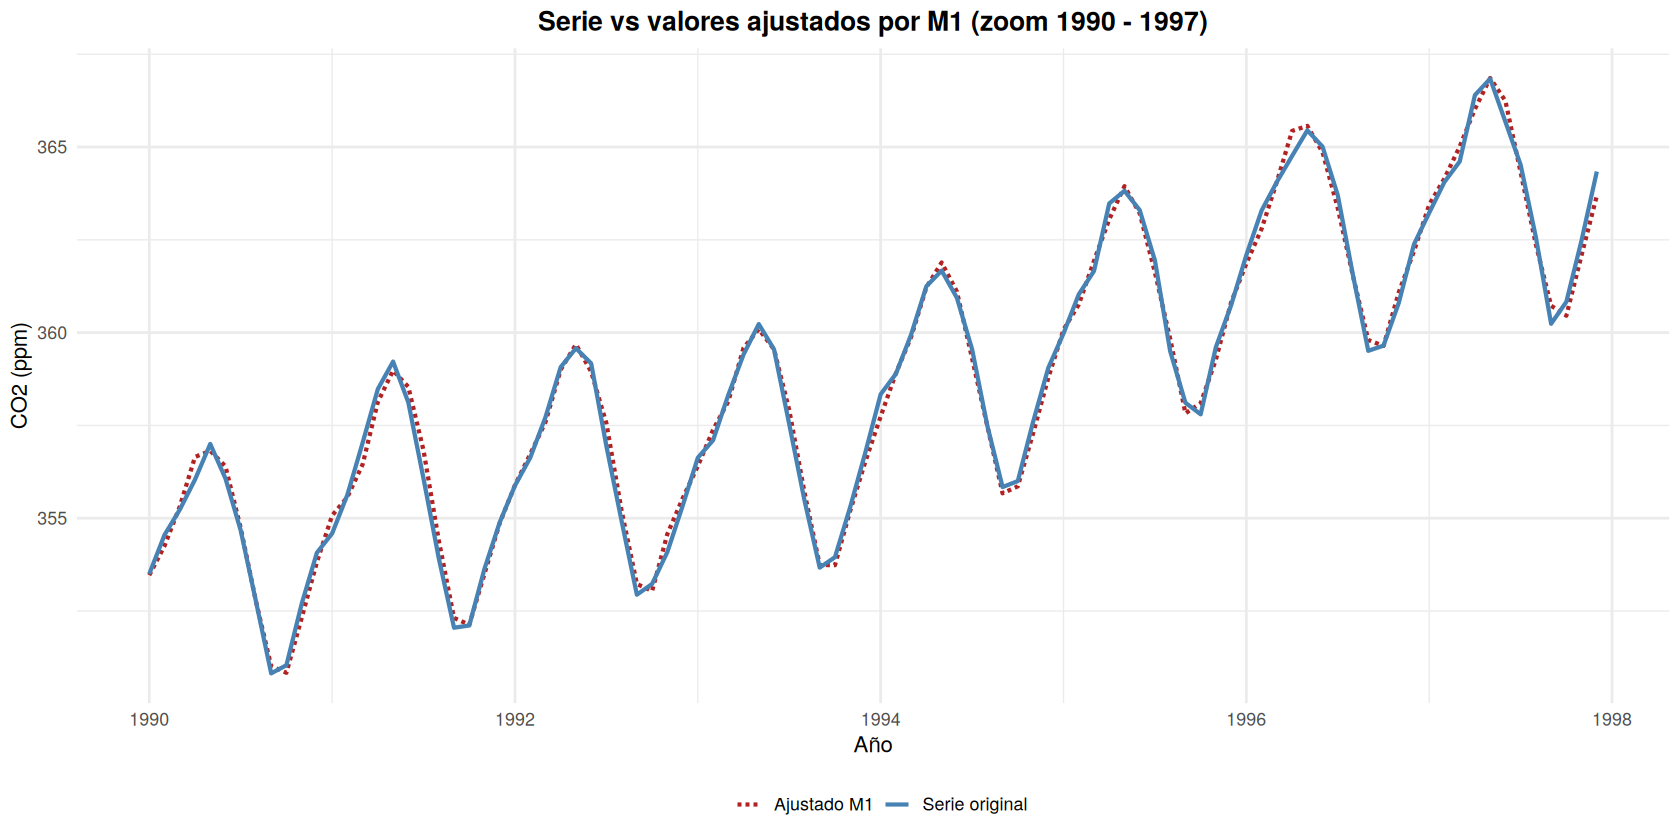

In [40]:
# Valores ajustados #
df_aj <- data.frame(Tiempo = rep(tiempo, 2), Valor = c(as.numeric(co2_ts), as.numeric(ajust)),
                    Serie = rep(c("Serie original", "Ajustado M1"), each = n))
ggplot(subset(df_aj, Tiempo >= 1990), aes(x = Tiempo, y = Valor, color = Serie, linetype = Serie)) +
  geom_line(linewidth = 0.9) +
  scale_color_manual(values = c("Serie original" = "steelblue", "Ajustado M1" = "firebrick")) +
  scale_linetype_manual(values = c("Serie original" = "solid", "Ajustado M1" = "dashed")) +
  labs(title = "Serie vs valores ajustados por M1 (zoom 1990 - 1997)", x = "Año", y = "CO2 (ppm)", color = "", linetype = "") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5, face = "bold"), legend.position = "bottom")

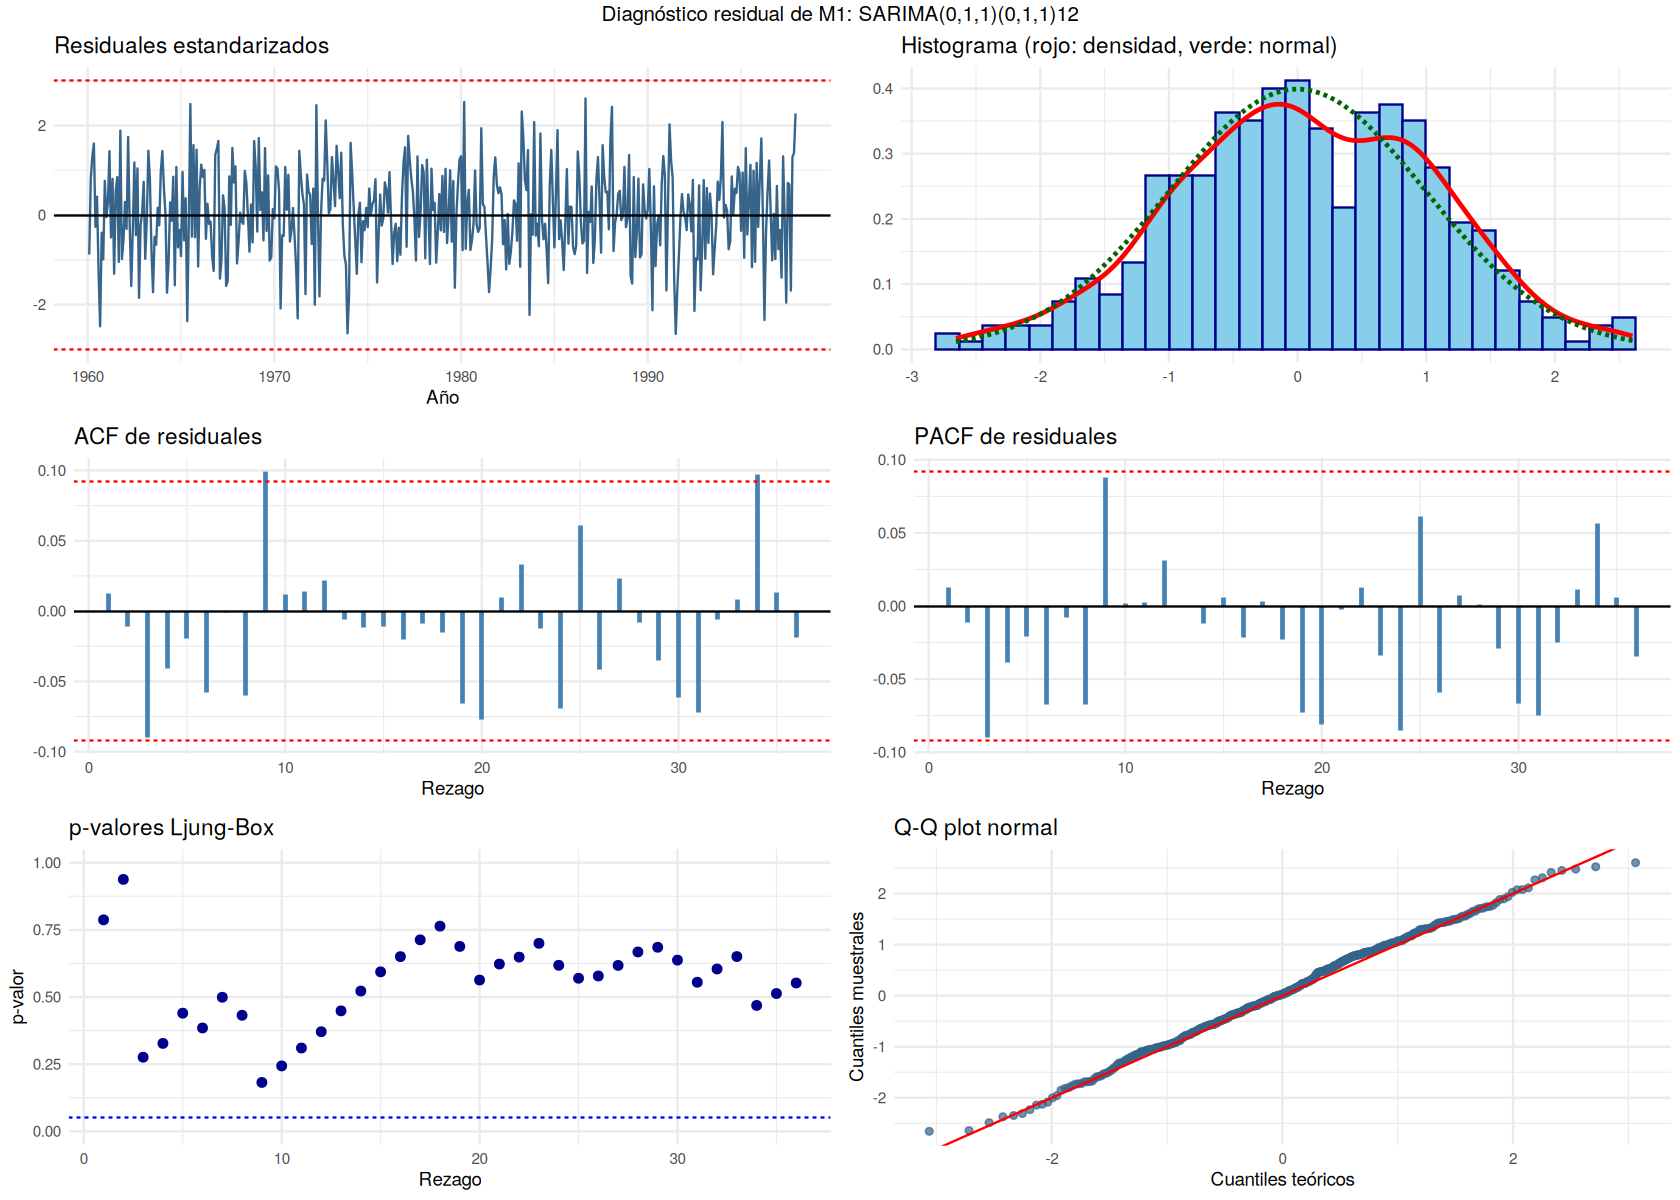

In [41]:
# Panel de diagnóstico residual (estilo del notebook de Amazon) #
lags <- 36
nr <- length(res_lim)
ci <- qnorm(0.975) / sqrt(nr)
t_res <- tiempo[-(1:13)]

g_r1 <- ggplot(data.frame(t = t_res, r = res_est), aes(t, r)) +
  geom_line(color = "steelblue4") +
  geom_hline(yintercept = c(-3, 0, 3), linetype = c("dashed", "solid", "dashed"), color = c("red", "black", "red")) +
  labs(title = "Residuales estandarizados", x = "Año", y = "") + theme_minimal()

g_r2 <- ggplot(data.frame(r = res_est), aes(r)) +
  geom_histogram(aes(y = after_stat(density)), bins = 30, fill = "skyblue", color = "darkblue") +
  geom_density(color = "red", linewidth = 1) +
  stat_function(fun = dnorm, color = "darkgreen", linewidth = 1, linetype = "dashed") +
  labs(title = "Histograma (rojo: densidad, verde: normal)", x = "", y = "") + theme_minimal()

acf_r  <- acf(res_lim, lag.max = lags, plot = FALSE)$acf[-1]
pacf_r <- pacf(res_lim, lag.max = lags, plot = FALSE)$acf[, 1, 1]
g_r3 <- ggplot(data.frame(l = 1:lags, v = acf_r), aes(l, v)) +
  geom_segment(aes(xend = l, yend = 0), color = "steelblue", linewidth = 1) +
  geom_hline(yintercept = c(-ci, ci), linetype = "dashed", color = "red") + geom_hline(yintercept = 0) +
  labs(title = "ACF de residuales", x = "Rezago", y = "") + theme_minimal()
g_r4 <- ggplot(data.frame(l = 1:lags, v = pacf_r), aes(l, v)) +
  geom_segment(aes(xend = l, yend = 0), color = "steelblue", linewidth = 1) +
  geom_hline(yintercept = c(-ci, ci), linetype = "dashed", color = "red") + geom_hline(yintercept = 0) +
  labs(title = "PACF de residuales", x = "Rezago", y = "") + theme_minimal()

p_lb <- sapply(1:lags, function(k) Box.test(res_lim, lag = k, type = "Ljung-Box", fitdf = 0)$p.value)
g_r5 <- ggplot(data.frame(l = 1:lags, p = p_lb), aes(l, p)) +
  geom_point(aes(color = p < 0.05), size = 2) +
  scale_color_manual(values = c("FALSE" = "darkblue", "TRUE" = "red"), guide = "none") +
  geom_hline(yintercept = 0.05, linetype = "dashed", color = "blue") + ylim(0, 1) +
  labs(title = "p-valores Ljung-Box", x = "Rezago", y = "p-valor") + theme_minimal()

qq <- qqnorm(res_est, plot.it = FALSE)
g_r6 <- ggplot(data.frame(x = qq$x, y = qq$y), aes(x, y)) +
  geom_point(color = "steelblue4", alpha = 0.7) + geom_abline(intercept = 0, slope = 1, color = "red") +
  labs(title = "Q-Q plot normal", x = "Cuantiles teóricos", y = "Cuantiles muestrales") + theme_minimal()

options(repr.plot.height = 10)
g_diag <- arrangeGrob(g_r1, g_r2, g_r3, g_r4, g_r5, g_r6, ncol = 2,
                      top = "Diagnóstico residual de M1: SARIMA(0,1,1)(0,1,1)12")
guardar(g_diag, "diagnostico_m1.png", alto = 10)
grid::grid.draw(g_diag)
options(repr.plot.height = 7)

<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

### **Autocorrelación: prueba de Ljung-Box**

$H_0$: los residuales no están autocorrelacionados hasta el rezago $h$ $\hspace{0.3cm} vs \hspace{0.3cm}$ $H_1$: hay autocorrelación en al menos un rezago.

Para que la prueba sea correcta, los grados de libertad se corrigen restando el número de parámetros estimados (`fitdf`).

</div>

In [42]:
data.frame(Rezago = c(12, 24, 36, 48),
           Q = sapply(c(12, 24, 36, 48), function(h) round(Box.test(res_lim, h, "Ljung-Box", fitdf = 2)$statistic, 2)),
           gl = c(12, 24, 36, 48) - 2,
           p_valor = sapply(c(12, 24, 36, 48), function(h) round(Box.test(res_lim, h, "Ljung-Box", fitdf = 2)$p.value, 4)))

Rezago,Q,gl,p_valor
<dbl>,<dbl>,<dbl>,<dbl>
12,12.98,10,0.2250
24,21.35,22,0.4993
36,34.24,34,0.4560
48,46.49,46,0.4520


<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

### **Metodologías para Contrastar Normalidad**

$H_0$: los residuales siguen una distribución normal $\hspace{0.3cm} vs \hspace{0.3cm}$ $H_1$: no siguen una distribución normal.

</div>

In [43]:
# Shapiro Wilk #
shapiro.test(res_lim)
# Kolmogorov-Smirnov (corrección de Lilliefors) #
lillie.test(res_lim)
# Jarque Bera #
jarqueberaTest(res_lim)


	Shapiro-Wilk normality test

data:  res_lim
W = 0.99634, p-value = 0.3845



	Lilliefors (Kolmogorov-Smirnov) normality test

data:  res_lim
D = 0.034716, p-value = 0.2019



Title:
 Jarque - Bera Normalality Test

Test Results:
  STATISTIC:
    X-squared: 1.8205
  P VALUE:
    Asymptotic p Value: 0.4024 


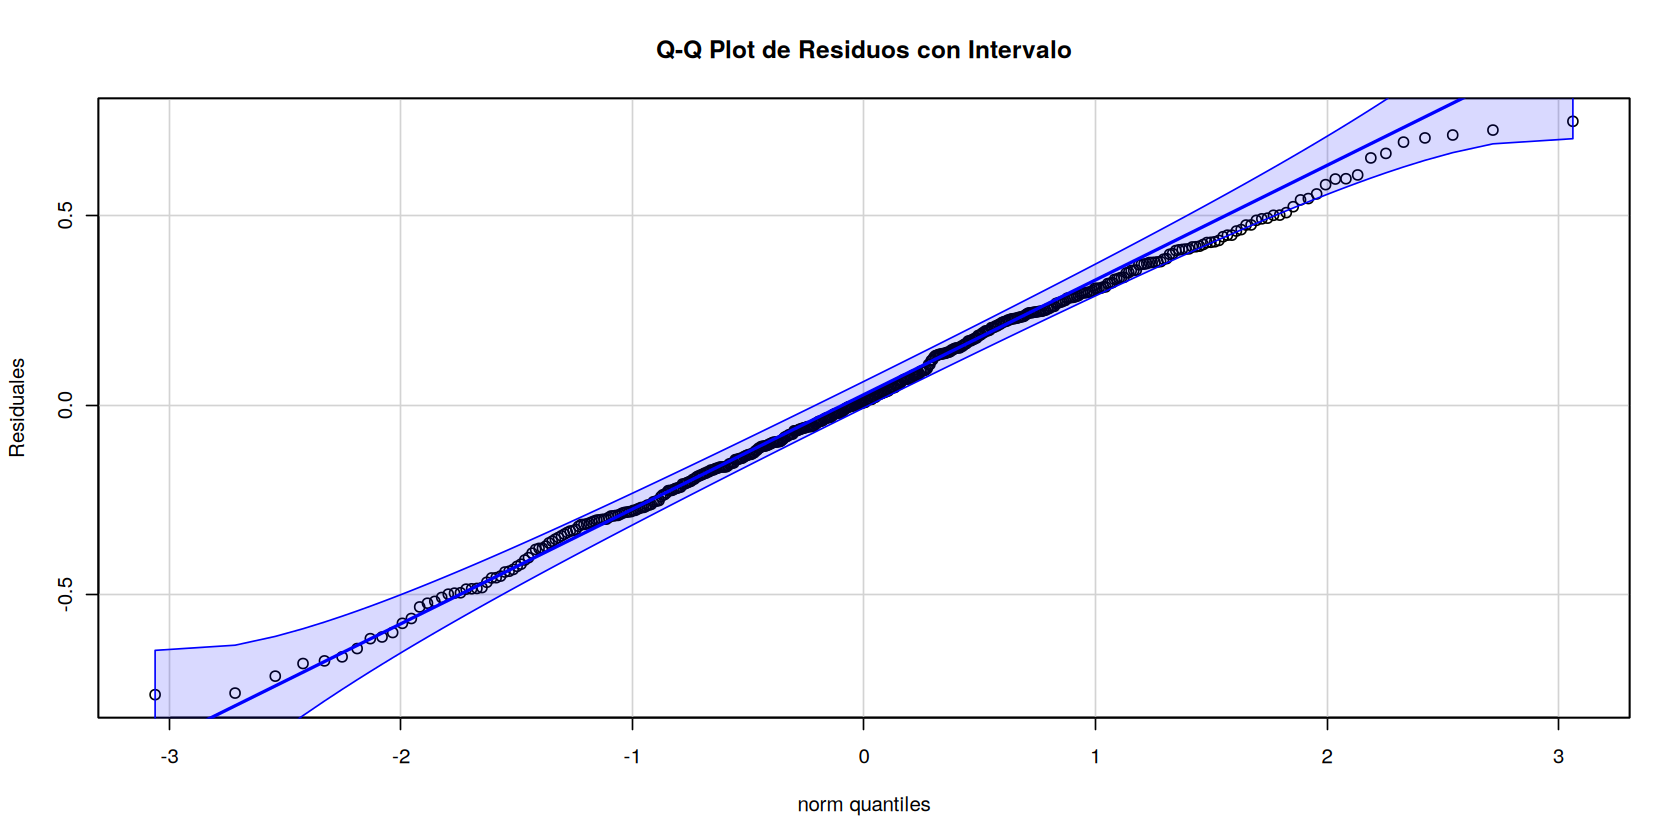

In [44]:
# Gráfico Q-Q con bandas de confianza (car) #
qqPlot(res_lim, envelope = 0.95, main = "Q-Q Plot de Residuos con Intervalo", ylab = "Residuales", id = FALSE)

<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

### **Homocedasticidad de los residuales**

Levene por año sobre los residuales, como se recomienda en el notebook de Amazon para confirmar que la varianza quedó estable. También miramos si hay efecto ARCH con Ljung-Box sobre los residuales al cuadrado.

</div>

In [45]:
anio_res <- factor(floor(t_res))
leveneTest(res_lim ~ anio_res)
# Ljung-Box sobre residuales al cuadrado (McLeod-Li) #
Box.test(res_lim^2, lag = 12, type = "Ljung-Box")

,Df,F value,Pr(>F)
,<int>,<dbl>,<dbl>
group,37,0.8621419,0.701898
,417,NA,NA



	Box-Ljung test

data:  res_lim^2
X-squared = 14.635, df = 12, p-value = 0.262


### **Comparación del diagnóstico para los cuatro candidatos**

In [46]:
diag_tabla <- function(mo, nombre) {
  r <- as.numeric(residuals(mo))[-(1:13)]
  k <- length(coef(mo))
  a <- factor(floor(tiempo[-(1:13)]))
  data.frame(Modelo = nombre,
             LB_12 = round(Box.test(r, 12, "Ljung-Box", fitdf = k)$p.value, 3),
             LB_24 = round(Box.test(r, 24, "Ljung-Box", fitdf = k)$p.value, 3),
             LB_36 = round(Box.test(r, 36, "Ljung-Box", fitdf = k)$p.value, 3),
             Shapiro = round(shapiro.test(r)$p.value, 3),
             Lilliefors = round(lillie.test(r)$p.value, 3),
             Jarque_Bera = round(jarqueberaTest(r)@test$p.value, 3),
             Levene = round(leveneTest(r ~ a)$`Pr(>F)`[1], 3),
             McLeod_Li = round(Box.test(r^2, 12, "Ljung-Box")$p.value, 3), row.names = NULL)
}
do.call(rbind, lapply(names(modelos), function(m) diag_tabla(modelos[[m]], m)))

Modelo,LB_12,LB_24,LB_36,Shapiro,Lilliefors,Jarque_Bera,Levene,McLeod_Li
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
M1,0.225,0.499,0.456,0.385,0.202,0.402,0.702,0.262
M2,0.233,0.488,0.452,0.569,0.092,0.421,0.606,0.203
M3,0.109,0.480,0.488,0.546,0.052,0.418,0.527,0.178
M4,0.081,0.557,0.599,0.392,0.027,0.352,0.662,0.139


<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

**Conclusión del diagnóstico.** Para **M1** todos los p-valores están por encima de 0.05: los residuales se comportan como **ruido blanco** (sin autocorrelación según Ljung-Box), con **varianza constante** (Levene y McLeod-Li) y **normales** (Shapiro-Wilk, Lilliefors y Jarque-Bera). Los otros tres candidatos también pasan casi todas las pruebas (M4 falla Lilliefors con p = 0.027 y M3 queda justo en el límite), así que no hay nada en los residuales que justifique sus parámetros adicionales. Por **parsimonia, BIC y significancia**, escogemos **M1: $SARIMA(0,1,1)\times(0,1,1)_{12}$**.

</div>

---
<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

<h1 align="center"><b>8. Pronóstico </b></h1>

Pronosticamos los 24 meses siguientes (1998 y 1999) con M1. Como no hubo transformación, no hace falta la corrección por sesgo de retransformación que se usó en Air Passengers.

</div>

In [47]:
# Pronósticos con horizonte de 24 meses #
fc_m1 <- forecast(mod, h = 24, level = c(80, 95))
tabla_fc <- data.frame(Mes = paste(meses[cycle(fc_m1$mean)], floor(time(fc_m1$mean))),
                       Pronostico = round(as.numeric(fc_m1$mean), 2),
                       Li_95 = round(as.numeric(fc_m1$lower[, 2]), 2),
                       Ls_95 = round(as.numeric(fc_m1$upper[, 2]), 2))
tabla_fc

Mes,Pronostico,Li_95,Ls_95
<chr>,<dbl>,<dbl>,<dbl>
Ene 1998,365.20,364.64,365.77
Feb 1998,366.05,365.38,366.72
Mar 1998,366.91,366.15,367.68
Abr 1998,368.26,367.42,369.11
May 1998,368.83,367.91,369.76
Jun 1998,368.14,367.15,369.14
Jul 1998,366.64,365.58,367.70
Ago 1998,364.59,363.47,365.71
Sep 1998,362.73,361.55,363.91


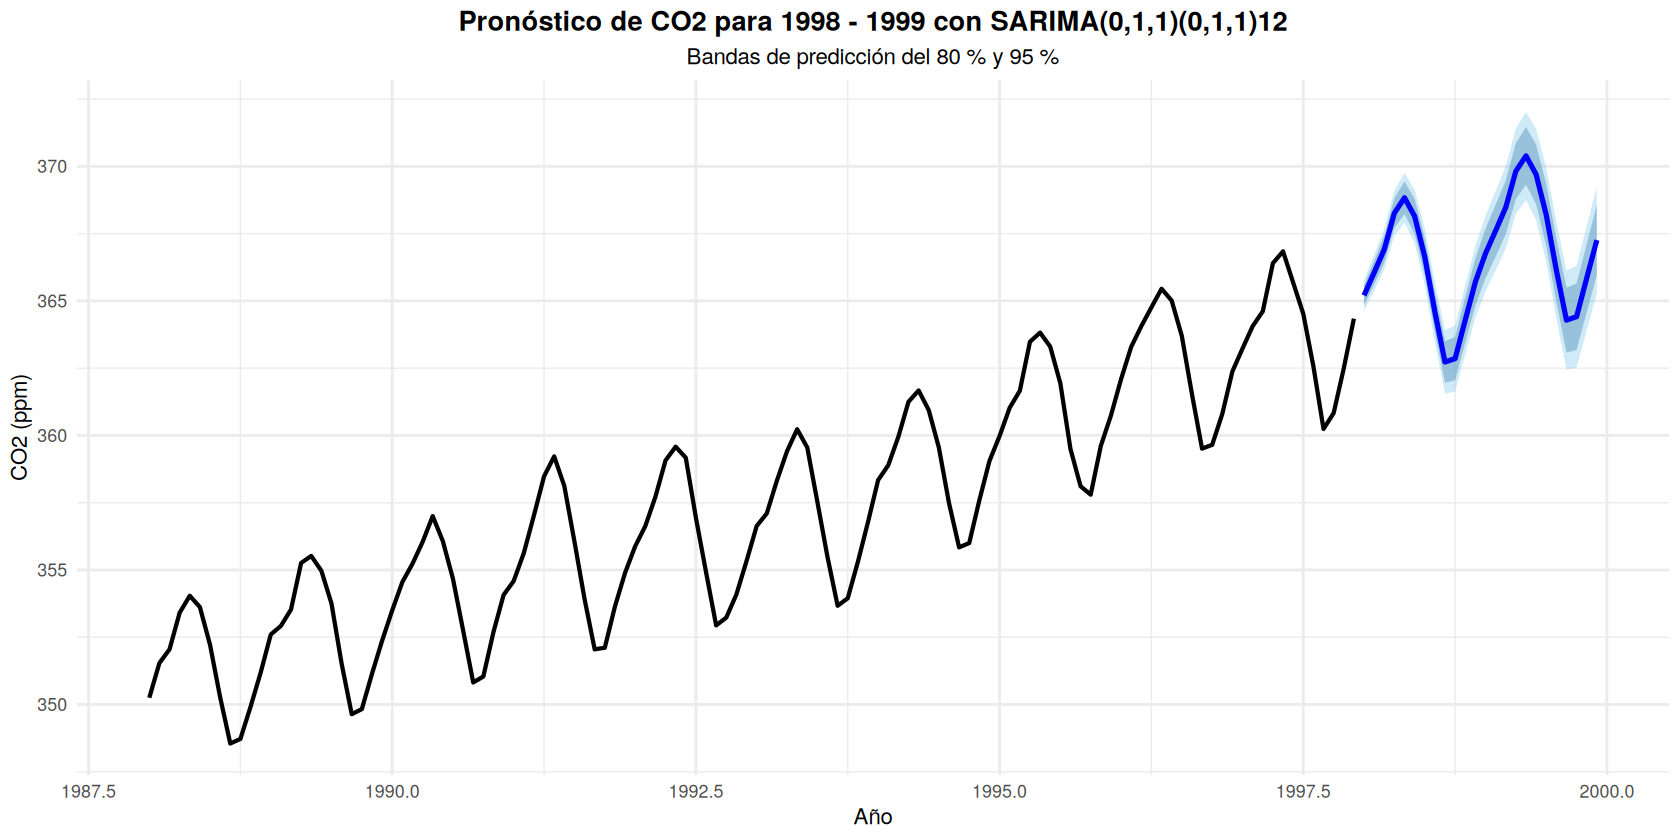

In [48]:
# Gráfico de los pronósticos #
df_fc <- data.frame(Tiempo = as.numeric(time(fc_m1$mean)), Pron = as.numeric(fc_m1$mean),
                    Li80 = as.numeric(fc_m1$lower[, 1]), Ls80 = as.numeric(fc_m1$upper[, 1]),
                    Li95 = as.numeric(fc_m1$lower[, 2]), Ls95 = as.numeric(fc_m1$upper[, 2]))
g_fc <- ggplot() +
  geom_line(data = subset(df_co2, Tiempo >= 1988), aes(x = Tiempo, y = CO2), color = "black", linewidth = 0.9) +
  geom_ribbon(data = df_fc, aes(x = Tiempo, ymin = Li95, ymax = Ls95), fill = "skyblue", alpha = 0.4) +
  geom_ribbon(data = df_fc, aes(x = Tiempo, ymin = Li80, ymax = Ls80), fill = "steelblue", alpha = 0.4) +
  geom_line(data = df_fc, aes(x = Tiempo, y = Pron), color = "blue", linewidth = 1.1) +
  labs(title = "Pronóstico de CO2 para 1998 - 1999 con SARIMA(0,1,1)(0,1,1)12",
       subtitle = "Bandas de predicción del 80 % y 95 %", x = "Año", y = "CO2 (ppm)") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"), plot.subtitle = element_text(hjust = 0.5))
guardar(g_fc, "pronostico_m1.png")
g_fc

In [49]:
# Forma alternativa con predict() #
pred_m1 <- predict(mod, n.ahead = 24, se.fit = TRUE)
data.frame(h = 1:24, Pronostico = round(as.numeric(pred_m1$pred), 2), EE = round(as.numeric(pred_m1$se), 3))[c(1, 6, 12, 18, 24), ]

,h,Pronostico,EE
,<int>,<dbl>,<dbl>
1,1,365.20,0.287
6,6,368.14,0.507
12,12,365.70,0.683
18,18,369.70,0.866
24,24,367.26,1.013


<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

El pronóstico conserva las dos cosas que tiene la serie: la tendencia creciente (en 1999 el promedio supera los 368 ppm) y el ciclo anual con pico en mayo. El error estándar crece con el horizonte, de unos 0.29 ppm a un mes hasta cerca de 1 ppm a dos años, porque el modelo tiene raíces unitarias.

</div>

In [50]:
paste("Promedio anual pronosticado 1998:", round(mean(fc_m1$mean[1:12]), 2), "ppm")
paste("Promedio anual pronosticado 1999:", round(mean(fc_m1$mean[13:24]), 2), "ppm")

[1] "Promedio anual pronosticado 1998: 365.85 ppm"

[1] "Promedio anual pronosticado 1999: 367.41 ppm"

<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

**Contraste con lo que pasó de verdad.** Estos años ya no están en la serie de R, pero se conocen: entre 1997 y 1998 el CO<sub>2</sub> en Mauna Loa subió 2.9 ppm, el salto anual más grande del registro hasta ese momento, asociado al fenómeno de El Niño 1997-1998, y el promedio de 1998 quedó alrededor de 366.7 ppm. El modelo pronostica un aumento de unos 2 ppm (de 363.82 a 365.85), así que se queda corto en cerca de 0.9 ppm. Es un buen recordatorio de que un SARIMA solo extrapola la dinámica que vio en los datos; un choque climático externo como El Niño no lo puede anticipar.

</div>

---
<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

<h1 align="center"><b>9. Capacidad de Pronóstico </b></h1>

Comparamos los cuatro SARIMA con tres métodos de referencia que no son de la familia ARIMA:

- **Holt-Winters aditivo** (suavizamiento exponencial triple, del notebook 1 del curso).
- **ETS automático** (`ets()`, suavizamiento exponencial en espacio de estados).
- **Ingenuo estacional** (el pronóstico de cada mes es el valor del mismo mes del año anterior). Es la línea base: un modelo que no le gane a este no sirve.

</div>

### **Analizar Desempeño por Trayectoria Ajustada (dentro de muestra)**

In [51]:
# Métricas dentro de muestra: ME, RMSE, MAE, MPE, MAPE, MASE #
cols <- c("ME", "RMSE", "MAE", "MAPE", "MASE")
fila <- function(nombre, a) data.frame(Modelo = nombre, t(round(a[1, cols], 4)))
acc_in <- do.call(rbind, lapply(names(modelos), function(m) fila(nombres_mod[m], accuracy(modelos[[m]]))))
hw_full  <- HoltWinters(co2_ts)
ets_full <- ets(co2_ts)
acc_in <- rbind(acc_in,
  fila("Holt-Winters", accuracy(forecast(hw_full, h = 1))),
  fila(paste0("ETS ", ets_full$method), accuracy(ets_full)),
  fila("Ingenuo estacional", accuracy(snaive(co2_ts))))
rownames(acc_in) <- NULL
acc_in

Modelo,ME,RMSE,MAE,MAPE,MASE
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
"SARIMA(0,1,1)(0,1,1)12",0.0154,0.2882,0.2301,0.0684,0.1817
"SARIMA(1,1,1)(0,1,1)12",0.0172,0.2875,0.2304,0.0685,0.1820
"SARIMA(1,1,1)(1,1,2)12",0.0174,0.2872,0.2304,0.0685,0.1820
"SARIMA(1,1,1)(2,1,2)12",0.0100,0.2822,0.2279,0.0677,0.1800
Holt-Winters,0.0164,0.3075,0.2488,0.0740,0.1965
"ETS ETS(M,Ad,M)",0.0439,0.2795,0.2242,0.0666,0.1771
Ingenuo estacional,1.2629,1.4079,1.2662,0.3724,1.0000


<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

Dentro de muestra todos los SARIMA tienen un MAPE cercano a 0.07 %, y M4 sale un poquito mejor porque tiene más parámetros. Pero el ajuste dentro de muestra siempre favorece a los modelos grandes, por eso lo importante es medir el pronóstico **fuera de muestra**.

</div>

### **Analizar Desempeño con Partición (80 % entrenamiento, 20 % prueba)**

In [52]:
# 1. Partición de los datos #
n_train <- round(0.80 * n)
n_test  <- n - n_train
co2_train <- ts(co2_ts[1:n_train], start = start(co2_ts), frequency = 12)
co2_test  <- ts(co2_ts[(n_train + 1):n], start = time(co2_ts)[n_train + 1], frequency = 12)
paste("Entrenamiento:", n_train, "meses, hasta", meses[cycle(co2_train)[n_train]], floor(time(co2_train)[n_train]))
paste("Prueba:", n_test, "meses, desde", meses[cycle(co2_test)[1]], floor(time(co2_test)[1]))

[1] "Entrenamiento: 374 meses, hasta Feb 1990"

[1] "Prueba: 94 meses, desde Mar 1990"

In [53]:
# 2. Funciones de pronóstico para cada método #
metodos <- c(
  lapply(especificaciones, function(e) function(y, h) forecast(ajustar(y, e), h = h, level = 95)),
  list(HW = function(y, h) forecast(HoltWinters(y), h = h, level = 95),
       ETS = function(y, h) forecast(ets(y), h = h, level = 95),
       SNAIVE = function(y, h) snaive(y, h = h, level = 95)))
etiquetas <- c(nombres_mod, HW = "Holt-Winters", ETS = "ETS", SNAIVE = "Ingenuo estacional")

# 3. Pronosticar el 20 % de prueba con cada método #
fc_test <- lapply(metodos, function(f) f(co2_train, n_test))
eval_test <- do.call(rbind, lapply(names(fc_test), function(m) {
  f <- fc_test[[m]]; real <- as.numeric(co2_test); pr <- as.numeric(f$mean)
  data.frame(Modelo = etiquetas[m],
             ME   = round(mean(real - pr), 3),
             RMSE = round(sqrt(mean((real - pr)^2)), 3),
             MAE  = round(mean(abs(real - pr)), 3),
             MAPE = round(MAPE(pr, real) * 100, 3),
             Cobertura_95 = round(mean(real >= f$lower[, 1] & real <= f$upper[, 1]) * 100, 1),
             row.names = NULL)
}))
eval_test[order(eval_test$RMSE), ]

,Modelo,ME,RMSE,MAE,MAPE,Cobertura_95
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
6,ETS,-0.964,1.138,0.992,0.277,100.0
5,Holt-Winters,-1.268,1.419,1.284,0.358,98.9
2,"SARIMA(1,1,1)(0,1,1)12",-1.289,1.443,1.307,0.364,97.9
3,"SARIMA(1,1,1)(1,1,2)12",-1.305,1.457,1.320,0.368,97.9
1,"SARIMA(0,1,1)(0,1,1)12",-1.315,1.467,1.331,0.371,100.0
4,"SARIMA(1,1,1)(2,1,2)12",-1.403,1.558,1.417,0.394,96.8
7,Ingenuo estacional,5.793,6.670,5.793,1.607,55.3


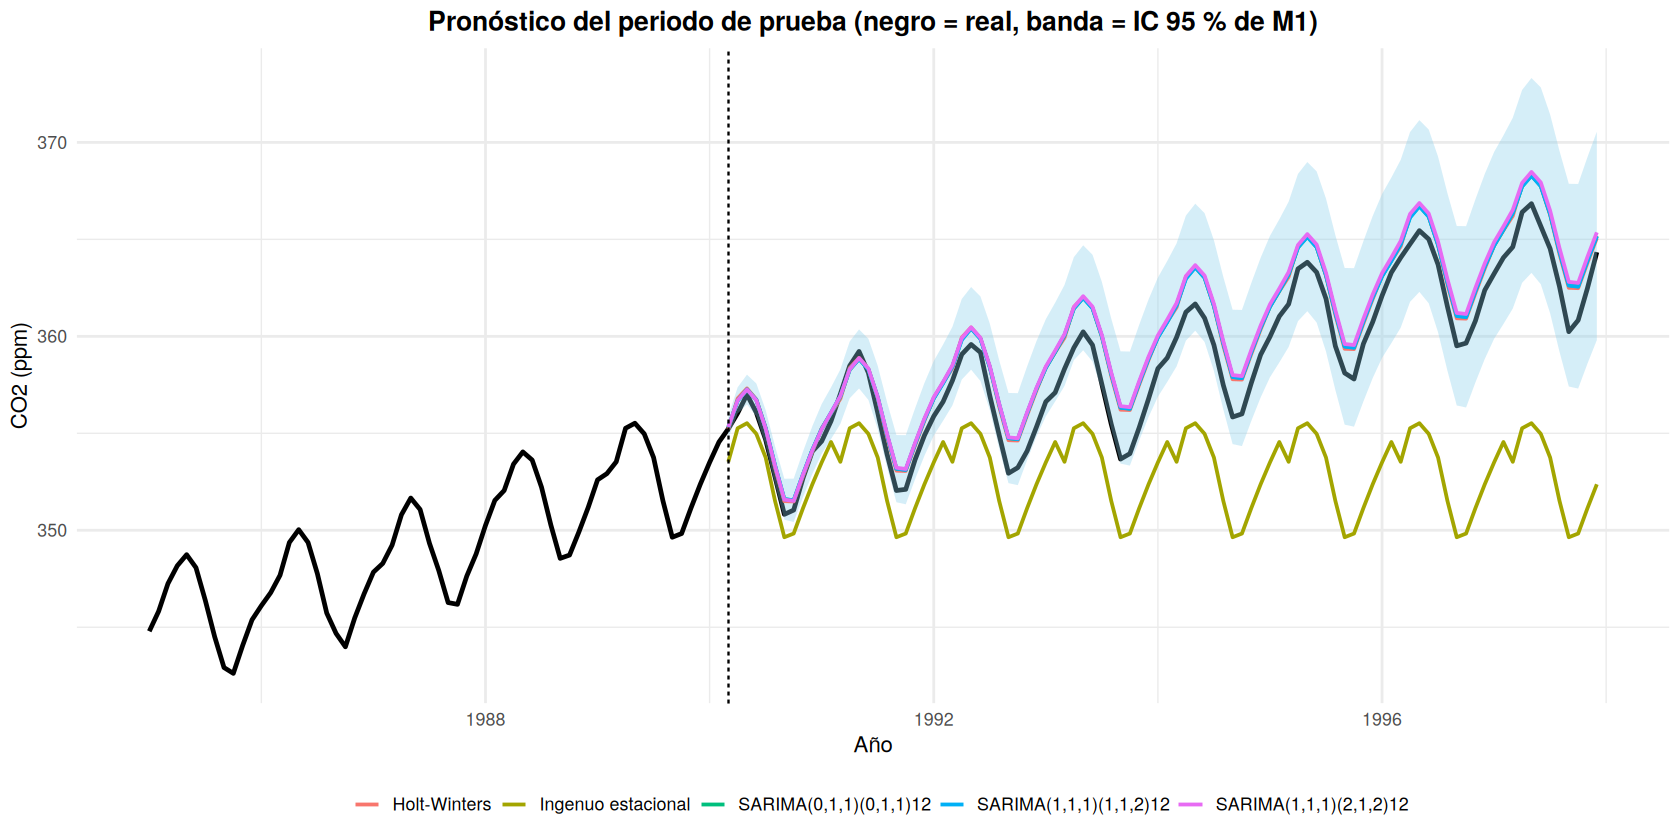

In [54]:
# 4. Gráfico de los pronósticos en el periodo de prueba #
df_test <- do.call(rbind, lapply(c("M1", "M3", "M4", "HW", "SNAIVE"), function(m)
  data.frame(Tiempo = as.numeric(time(co2_test)), Valor = as.numeric(fc_test[[m]]$mean), Modelo = etiquetas[m])))
g_test <- ggplot() +
  geom_line(data = subset(df_co2, Tiempo >= 1985), aes(x = Tiempo, y = CO2), color = "black", linewidth = 1) +
  geom_ribbon(data = data.frame(Tiempo = as.numeric(time(co2_test)), Li = as.numeric(fc_test$M1$lower), Ls = as.numeric(fc_test$M1$upper)),
              aes(x = Tiempo, ymin = Li, ymax = Ls), fill = "skyblue", alpha = 0.35) +
  geom_line(data = df_test, aes(x = Tiempo, y = Valor, color = Modelo), linewidth = 0.8) +
  geom_vline(xintercept = as.numeric(time(co2_test))[1], linetype = "dashed") +
  labs(title = "Pronóstico del periodo de prueba (negro = real, banda = IC 95 % de M1)",
       x = "Año", y = "CO2 (ppm)", color = "") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5, face = "bold"), legend.position = "bottom")
guardar(g_test, "prueba_80_20.png")
g_test

<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

Aquí el ganador es **ETS**, seguido de Holt-Winters y los SARIMA, que quedan muy parejos entre sí (RMSE entre 1.44 y 1.56 ppm). La razón está en el ME negativo: el entrenamiento termina en febrero de 1990, justo después de los años 80 en los que el CO<sub>2</sub> creció más rápido, y los modelos extrapolan ese ritmo; pero en 1991 a 1993 el crecimiento se frenó y todos **sobreestiman**. El ETS escogido tiene tendencia **amortiguada** (la pendiente se va aplanando con el horizonte), y en este corte en particular eso le ayudó. Todos los modelos le ganan con mucha ventaja al ingenuo estacional, que no tiene tendencia y además tiene una cobertura de solo 55 %.

Una sola partición con un horizonte de casi 8 años depende mucho de dónde se corte, por eso es importante la validación cruzada.

</div>

---
### **Analizar Desempeño con Validación Cruzada (ventana expansiva)**

<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

La partición única depende mucho de dónde se corte. Por eso hacemos la validación cruzada con **ventana expansiva** del curso: se empieza entrenando con el 50 % de la serie, se pronostica el bloque siguiente, se agrega ese bloque al entrenamiento y se repite, en 10 pliegues. Así cada modelo se evalúa en 10 periodos distintos.

</div>

In [55]:
# 1. Configuración #
k_folds   <- 10
min_train <- floor(n * 0.50)
step      <- floor((n - min_train) / k_folds)
paste("Entrenamiento inicial:", min_train, "meses; bloque de prueba por pliegue:", step, "meses")

# 2. Bucle de validación cruzada #
cv <- list()
for (i in 1:k_folds) {
  train_end <- min_train + (i - 1) * step
  test_end  <- if (i == k_folds) n else min_train + i * step
  y_tr <- ts(co2_ts[1:train_end], start = start(co2_ts), frequency = 12)
  real <- as.numeric(co2_ts[(train_end + 1):test_end])
  for (m in names(metodos)) {
    pr <- tryCatch(as.numeric(metodos[[m]](y_tr, length(real))$mean), error = function(e) rep(NA, length(real)))
    cv[[length(cv) + 1]] <- data.frame(Pliegue = i, Modelo = etiquetas[m],
                                       MAPE = mean(abs((real - pr) / real)) * 100,
                                       RMSE = sqrt(mean((real - pr)^2)))
  }
}
cv <- do.call(rbind, cv); rownames(cv) <- NULL

[1] "Entrenamiento inicial: 234 meses; bloque de prueba por pliegue: 23 meses"

In [56]:
# 3. Estadísticas de los pliegues #
res_cv <- aggregate(cbind(MAPE, RMSE) ~ Modelo, data = cv, FUN = function(z) c(Media = mean(z), DE = sd(z)))
res_cv <- data.frame(Modelo = res_cv$Modelo,
                     MAPE_medio = round(res_cv$MAPE[, "Media"], 4), MAPE_DE = round(res_cv$MAPE[, "DE"], 4),
                     RMSE_medio = round(res_cv$RMSE[, "Media"], 4), RMSE_DE = round(res_cv$RMSE[, "DE"], 4))
res_cv[order(res_cv$RMSE_medio), ]

,Modelo,MAPE_medio,MAPE_DE,RMSE_medio,RMSE_DE
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
6,"SARIMA(1,1,1)(1,1,2)12",0.1245,0.0627,0.5324,0.2498
4,"SARIMA(0,1,1)(0,1,1)12",0.1263,0.0607,0.5394,0.2430
5,"SARIMA(1,1,1)(0,1,1)12",0.1272,0.0613,0.5426,0.2460
7,"SARIMA(1,1,1)(2,1,2)12",0.1322,0.0637,0.5635,0.2600
1,ETS,0.1437,0.1227,0.6116,0.4892
2,Holt-Winters,0.1522,0.0670,0.6260,0.2621
3,Ingenuo estacional,0.6436,0.1535,2.4146,0.5654


In [57]:
# Pliegues ganados por cada modelo (menor RMSE en el pliegue) #
ganador <- sapply(split(cv, cv$Pliegue), function(d) d$Modelo[which.min(d$RMSE)])
table(ganador)

ganador
                   ETS           Holt-Winters SARIMA(0,1,1)(0,1,1)12 
                     2                      1                      1 
SARIMA(1,1,1)(1,1,2)12 SARIMA(1,1,1)(2,1,2)12 
                     2                      4 

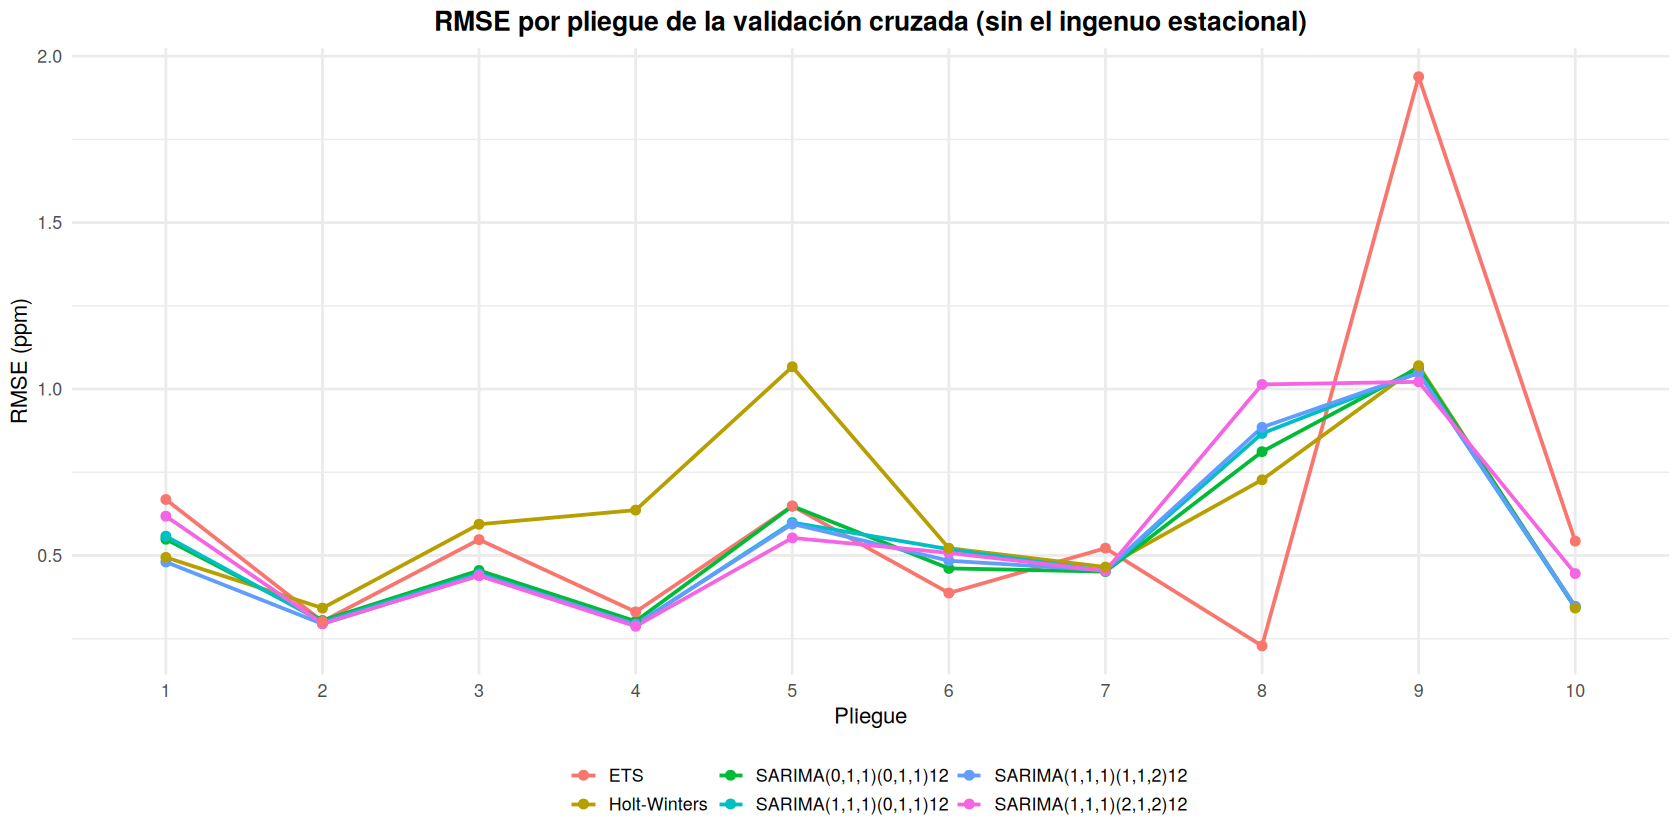

In [58]:
# 4. Gráfico de los RMSE por pliegue #
cv_plot <- subset(cv, Modelo != "Ingenuo estacional")
g_cv <- ggplot(cv_plot, aes(x = factor(Pliegue), y = RMSE, color = Modelo, group = Modelo)) +
  geom_line(linewidth = 0.8) + geom_point(size = 2) +
  labs(title = "RMSE por pliegue de la validación cruzada (sin el ingenuo estacional)",
       x = "Pliegue", y = "RMSE (ppm)", color = "") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5, face = "bold"), legend.position = "bottom")
guardar(g_cv, "validacion_cruzada.png")
g_cv

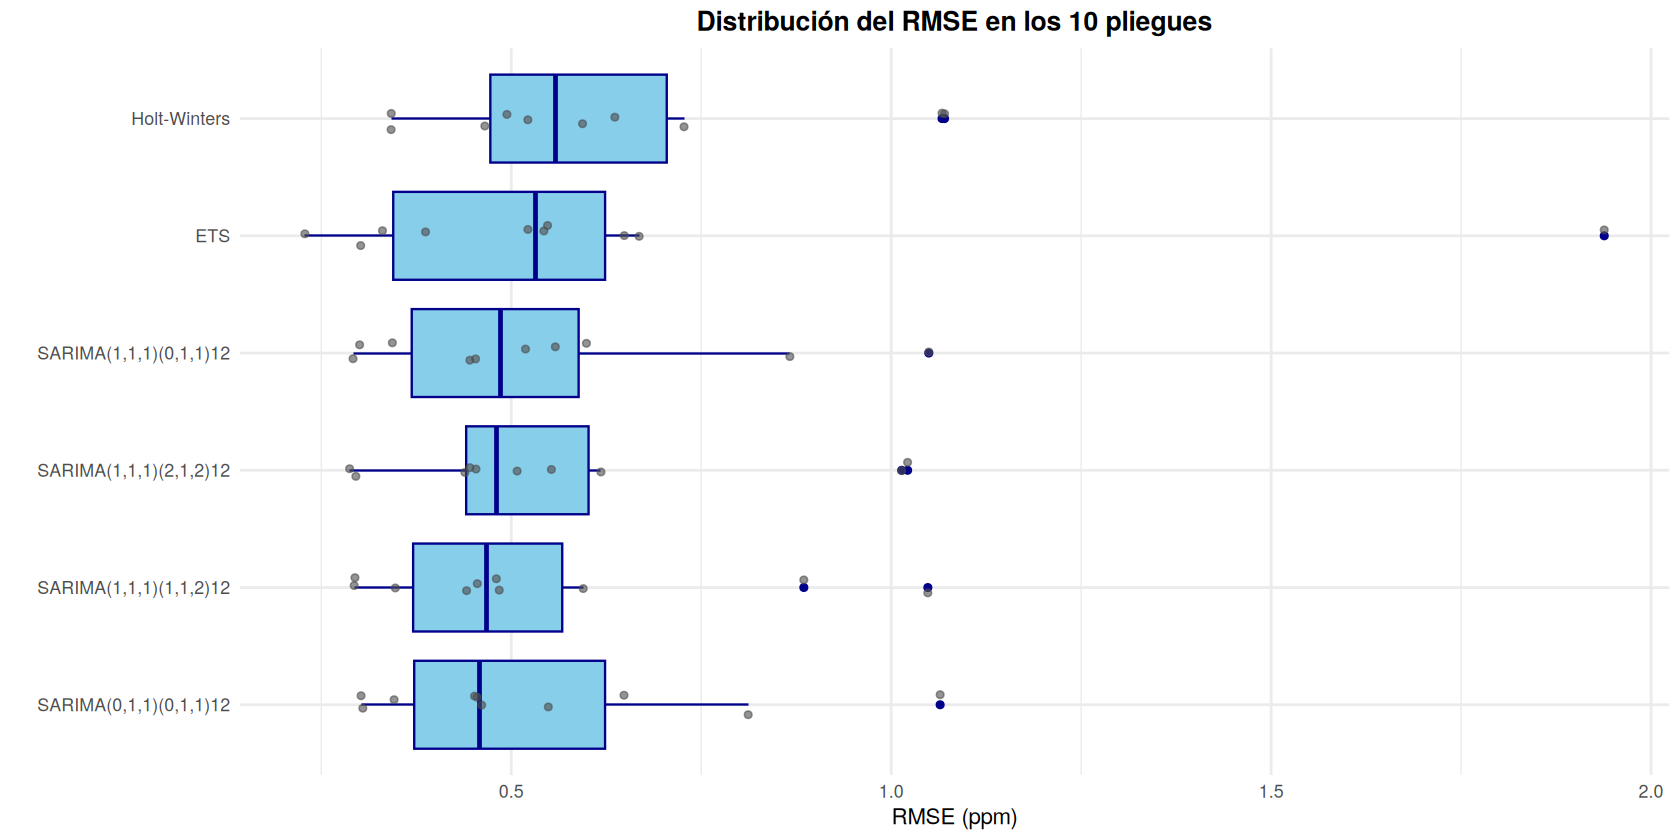

In [59]:
ggplot(cv_plot, aes(x = reorder(Modelo, RMSE, median), y = RMSE)) +
  geom_boxplot(fill = "skyblue", color = "darkblue") +
  geom_jitter(width = 0.1, color = "grey30", alpha = 0.6) +
  coord_flip() +
  labs(title = "Distribución del RMSE en los 10 pliegues", x = "", y = "RMSE (ppm)") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5, face = "bold"))

<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

### **Lectura de la validación cruzada**

Con 10 orígenes distintos y bloques de 23 meses el resultado cambia: los **cuatro SARIMA quedan de primeros** en RMSE y MAPE promedio, por delante de ETS y Holt-Winters, y el ingenuo estacional queda muy lejos. Entre los SARIMA las diferencias son mínimas (RMSE promedio de 0.53 a 0.56 ppm, con desviaciones de 0.24 a 0.26 entre pliegues), mucho más pequeñas que la variación de un pliegue a otro. M1, con solo dos parámetros, queda a menos del 2 % del mejor. El ETS, que ganó en la partición 80/20, es el más inestable entre pliegues (su DE es el doble que la de los SARIMA).

### **Pronóstico a un paso (origen móvil)**

En la práctica el modelo se usa mes a mes: cada vez que llega un dato nuevo se pronostica el siguiente. Para medir eso, fijamos los coeficientes estimados con el entrenamiento y pronosticamos un paso adelante a lo largo de todo el periodo de prueba.

</div>

In [60]:
un_paso <- do.call(rbind, lapply(names(especificaciones), function(m) {
  fit_tr <- ajustar(co2_train, especificaciones[[m]])
  fit_all <- Arima(co2_ts, model = fit_tr)     # mismos coeficientes, filtrados sobre toda la serie
  e <- (co2_ts - fitted(fit_all))[(n_train + 1):n]
  data.frame(Modelo = nombres_mod[m], RMSE_1paso = round(sqrt(mean(e^2)), 4),
             MAE_1paso = round(mean(abs(e)), 4), row.names = NULL)
}))
hw_tr <- HoltWinters(co2_train)
e_hw <- sapply((n_train + 1):n, function(t) {
  y <- ts(co2_ts[1:(t - 1)], start = start(co2_ts), frequency = 12)
  co2_ts[t] - predict(HoltWinters(y, alpha = hw_tr$alpha, beta = hw_tr$beta, gamma = hw_tr$gamma), 1)
})
rbind(un_paso, data.frame(Modelo = "Holt-Winters", RMSE_1paso = round(sqrt(mean(e_hw^2)), 4), MAE_1paso = round(mean(abs(e_hw)), 4)))

Modelo,RMSE_1paso,MAE_1paso
<chr>,<dbl>,<dbl>
"SARIMA(0,1,1)(0,1,1)12",0.3017,0.2450
"SARIMA(1,1,1)(0,1,1)12",0.3008,0.2473
"SARIMA(1,1,1)(1,1,2)12",0.3012,0.2473
"SARIMA(1,1,1)(2,1,2)12",0.2994,0.2452
Holt-Winters,0.3148,0.2548


<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

A un paso todos los modelos aciertan con un error de unas 0.30 ppm, el mismo tamaño que la desviación estándar de las innovaciones ($\hat\sigma \approx 0.29$). Los SARIMA quedan prácticamente empatados y un poco mejor que Holt-Winters. Es decir, la complejidad extra de M2, M3 y M4 no se traduce en mejores pronósticos.

</div>

---
<div style="text-align: justify; line-height: 1.5; font-size: 18px;">

<h1 align="center"><b>10. Conclusiones </b></h1>

1. La serie `co2` tiene una **tendencia creciente con pendiente variable** (0.85 ppm por año en los 60, 1.6 en los 80 y 1.4 en los 90) y una **estacionalidad anual aditiva** muy estable, con pico en mayo y valle en septiembre-octubre.
2. El suavizamiento con la **media móvil 2×12** separa limpiamente la tendencia; las ventanas cortas (3 y 5 meses) no alcanzan a quitar la estacionalidad. La estacionalidad explica cerca del 98 % de la variación que queda después de quitar la tendencia.
3. La **varianza es estable** (Levene no rechaza y la leve relación entre dispersión y nivel es despreciable), así que no hizo falta Box-Cox. El $\lambda$ de Guerrero sugiere logaritmo, pero en el rango de la serie el logaritmo es prácticamente igual a la serie original.
4. La serie **no es estacionaria** (ADF no rechaza y KPSS rechaza). Hicieron falta **una diferencia ordinaria y una estacional**: $(1-B)(1-B^{12})$.
5. La ACF y la PACF de la serie diferenciada, junto con el **BIC**, apuntan al modelo de aerolíneas **$SARIMA(0,1,1)\times(0,1,1)_{12}$**, con dos parámetros muy significativos y residuales que pasan todas las pruebas (Ljung-Box, normalidad, Levene y McLeod-Li).
6. Los modelos más grandes que escogen el AIC y `auto.arima` tienen parámetros no significativos o polinomios estacionales que se contrarrestan, y no mejoran el pronóstico de forma consistente.
7. En capacidad de pronóstico los SARIMA son los mejores en la validación cruzada (RMSE promedio cercano a 0.54 ppm a horizontes de hasta 2 años), le ganan siempre al ingenuo estacional y a un paso tienen un error de 0.30 ppm, menos del 0.1 % del nivel. En la partición única 80/20 ganó el ETS amortiguado, pero por una particularidad del corte (la desaceleración de 1991 a 1993).
8. **Modelo escogido: M1**, por parsimonia, significancia, BIC y desempeño de pronóstico prácticamente igual al de los modelos más grandes.

La aplicación Shiny que acompaña este notebook (`app/app.R`) permite repetir todo este análisis de forma interactiva y comparar los modelos.

</div>

---
#  **¡FINAL!**
---